# Case 2 — MSME Credit Scoring: Which Signals Predict Default, Does the Model Separate Good from Bad, Is It Still Stable, and Where Should We Cut?

**Reference:** Case Study 11 — *Lendingkart: Cash-Flow-Based MSME Underwriting with XGBoost* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Chief Risk Officer, Credit Policy, Underwriting, Collections
**Data:** ⚠️ **SYNTHETIC** main dataset (≈ 50,000 MSME applications, Apr 2019 – Mar 2021) built to imitate bank-statement + GST + bureau underwriting. Public **UCI Statlog German Credit** data is used *only* as a structural cross-check (Section 4.4). See `decision.md` D-2-01.
**Reproducibility:** seed = 42. Run with `python -m nbconvert --to notebook --execute --inplace 02_msme_credit_scoring.ipynb`.

## 0. Executive Summary for Business

*(Written last; based on synthetic data built to Lendingkart's documented feature families.)*

- **The problem:** MSMEs are under-served because manual underwriting is slow and bureau data is thin. We need a score that uses bank-statement and GST data, plus clear cut-offs.
- **What predicts default:** **cheque bounces** (each bounce raises the odds of default by 50%), **loans declined elsewhere** (+32% each), **low minimum balance** (−14% risk per doubling), **shrinking inflows** (−13% risk per +10 pp of growth), **bureau score** (−27% risk per +50 points), business age and Tier-3 location (+47%). Industry and sourcing channel add nothing in normal times.
- **The model works:** KS 39 and Gini 0.52 on unseen applicants. The riskiest 10% of applicants contain 38% of all future defaulters. Buckets A→F run cleanly from 1.3% to 27.5% bad rate. It also works for new-to-credit businesses with no bureau score.
- **Growth without extra risk:** at the same bad rate as a typical manual policy, the model approves **68% more businesses** (Lendingkart documents about 50%).
- **Stability:** in a COVID-like shock the model still ranks borrowers well (KS 38.5), but the applicant population shifts (PSI 0.15) and **hospitality and transport loans default 26–60% more than predicted**. It needs an industry overlay and recalibration.
- **₹ impact:** at the recommended cut-off of **575**, per 10,000 applications, ≈ ₹1,037 crore is disbursed at a 4.4% bad rate for ≈ **₹52 crore expected profit** (range ₹22–65 crore). In a shock, raise the cut-off to **600**.
- **I recommend:** adopt the logistic scorecard as the champion (it beats an untuned XGBoost and is fully explainable), auto-approve buckets A–B (Zero-Touch), and monitor PSI monthly with a pre-agreed shock playbook.

## 1. The Problem in Simple English

Meet Ramesh, who runs a 4-year-old garment-trading business in Surat. He needs ₹8 lakh of working capital before the festive season. A bank will ask for collateral and audited financials he does not have. Most of his peers are in the same position: the reference file notes that "only 16%" of MSMEs receive formal credit. His **bank statement**, however, tells a rich story: how much money flows in every month, whether his balance ever runs dry, whether his cheques bounce, and whether sales are growing. His **GST returns** confirm his turnover. A digital NBFC can read all of this in seconds.

The Chief Risk Officer needs four answers before trusting a model to approve loans like Ramesh's automatically:

1. **Which signals actually predict default?** (Not just "the model says so".)
2. **Does the model separate good borrowers from bad ones?** And by how much compared with a simple manual rule?
3. **Is it still stable today?** Our model was built on pre-COVID applications. Does it still work after a shock like COVID, when, as the case notes, "ITR and bureau data weakened"?
4. **Where do we set the cut-off, and what are the risk buckets?** What do we gain in approvals and lose in credit losses, in ₹?

What it costs to get this wrong: approve too many bad borrowers, and every default on a ₹8 lakh unsecured loan loses roughly ₹4 lakh after recoveries. Reject too many good ones, and we lose the interest income and the customer, and leave Ramesh without credit.

## 2. Reference from the Case File

### (a) What Lendingkart actually did — *documented* (quoted from the reference file)

| Item | Documented fact |
|---|---|
| Business problem | "Most MSMEs lack formal credit ('only 16%' receive it, per AIM). Manual underwriting is slow and expensive. Bureau data is thin for new-to-credit businesses." |
| Business question | "From bank statements, GST and other data, how risky is this MSME? How much can it borrow over 1, 2 or 3 years?" |
| Data | Bank statements ("balances, credits/debits, cheque returns"), GST ("business turnover signals"), bureau & application data; CIO.com also mentions social media, e-commerce and utility data |
| Feature families | "5,000+ derived variables (CIO.com says 'close to 10,000')": **Aggregates** (minimum closing balance, maximum credit months), **Trended** variables, **Negative indicators** (cheque returns, credit declines), **Momentum** (QoQ / HoH / YoY growth), **Balance-transfer triggers** |
| Model | "**XGBoost**, with explainability" |
| Outputs | "Lendingkart Score (**300–900**), Risk Bucket (**A–F**), loan amount for 1/2/3-year tenure, expected bad amount rate, key ratios such as **EMI/ADB** (EMI to average daily balance)" |
| Validation | "Three types of statistical tests are run on the model to evaluate the model predictability and dependability on a sample from time to time". The tests are not named. "Model behaviour after COVID (when ITR and bureau data weakened) was discussed." |
| Metrics | "KS / Gini / AUC not disclosed" |
| Decision | "About 40% go through a 'Zero Touch' process with no manual underwriting." |
| Impact | "About **50% higher approval rates** vs manual underwriting"; "about 40% of customers on Zero Touch, with 75% TAT reduction"; "average scoring time about 3.5 seconds"; models "perform better for new-to-credit MSMEs that have CIBIL scores of **651–700**" |

**Sources:**
- AIM interview with Abhishek Singh, Chief Analytics Officer (republished, undated) — https://www.lendingkartcareers.com/how-lendingkart-uses-machine-learning/
- CIO.com (14 Sep 2020) — https://www.cio.com/article/193986/
- Lendingkart Finance Annual Report FY2021 — https://www.lendingkartfinance.com/wp-content/uploads/2022/02/Annual-Report-2021.pdf

### (b) What *we* are simulating or adding — *our professional approach*

| Item | Our choice |
|---|---|
| Data | 50,000 synthetic applications (plus 2% re-applications), Apr 2019 – Mar 2021, with all five documented feature families (balance-transfer triggers excluded; see D-2-03). |
| Target | **90+ days past due (DPD) within 12 months** of disbursal (the brief's definition; Lendingkart's own target is not disclosed). |
| Validation design | Development = Apr 2019 – Mar 2020 (pre-shock), split 70/30 into train/test. **Out-of-time (OOT)** = Apr 2020 – Mar 2021, with a COVID-like shock. |
| The "three types of statistical tests" | We make them explicit: **discrimination** (KS, Gini/AUC, gains/lift), **calibration** (Hosmer–Lemeshow, calibration plot) and **stability** (PSI/CSI). |
| Models | An interpretable logistic-regression scorecard (statsmodels) as the champion candidate; one default-parameter XGBoost (the documented algorithm) as the challenger |
| Business layer | 300–900 score, buckets A–F, cut-off trade-off table, expected loss = PD × LGD × EAD |

## 3. Business Question → Analytical Question → Statistical Hypotheses

Fixed **before** looking at the results.

| Level | Statement |
|---|---|
| **Business question** | Can we approve more MSMEs automatically without raising credit losses, and where should the cut-off be? |
| **Analytical Q1** | Which application-time signals differ between borrowers who later default and those who do not? |
| **Analytical Q2** | How well does a model built on pre-shock data rank-order risk on unseen and later (post-shock) applicants? |
| **Analytical Q3** | Are its predicted default probabilities accurate (calibrated)? |
| **Analytical Q4** | Has the applicant population shifted since development? |
| **Analytical Q5** | What approval rate, bad rate and ₹ expected loss result at each cut-off? |

**Statistical hypotheses**

- **H1 (categorical signals):** H0: default rate is independent of the category (industry, city tier, constitution, channel, GST registration, new-to-credit). Chi-square test, Holm-corrected.
- **H2 (numeric signals):** H0: the distribution of feature X is the same for defaulters and non-defaulters. Mann–Whitney U, Holm-corrected.
- **H3 (model coefficients):** H0: βⱼ = 0 for each feature in the logistic model (Wald test).
- **H4 (discrimination):** H0: AUC = 0.5 (the model is no better than random). We also report the AUC difference between XGBoost and logistic regression, with a bootstrap CI.
- **H5 (calibration):** H0: observed default = predicted PD in every risk decile (Hosmer–Lemeshow).
- **H6 (stability):** PSI is a descriptive index, not a hypothesis test. Industry thresholds: < 0.10 stable, 0.10–0.25 monitor, > 0.25 significant shift.

**Definitions**

- **Primary metric:** **KS** (Kolmogorov–Smirnov) statistic on the test sample: the maximum gap between the cumulative share of bads and the cumulative share of goods when applicants are sorted by score. It is the standard Indian-lending discrimination metric. We also report Gini = 2·AUC − 1.
- **Guardrails:** calibration error (predicted vs actual default rate), score PSI, monotonic bad rate across buckets A → F, and the bad rate of approved loans at the chosen cut-off.
- **Unit of analysis:** one unique business's first application in the window.
- **Significance level:** α = 0.05. Multiple tests are Holm-corrected.
- **Decision rule:** the model is fit for use if (i) test KS ≥ 30 and OOT KS ≥ 25 (common Indian-NBFC acceptance bands, D-2-11); (ii) bad rate rises monotonically from bucket A to F; (iii) score PSI < 0.25, or, if PSI ≥ 0.25, the model is recalibrated before use. The cut-off is the score that maximises expected profit, subject to the bad rate of approved loans being ≤ 5%.

In [1]:
# ---- Setup ---------------------------------------------------------------
import sys, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
import xgboost as xgb

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("Environment ready | xgboost", xgb.__version__, "| statsmodels", sm.__version__)

Environment ready | xgboost 3.2.0 | statsmodels 0.14.6


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Indian MSME bank-statement / GST / bureau data with loan outcomes (data.gov.in, RBI, SIDBI, GitHub) | **None openly available.** SIDBI/TransUnion MSME Pulse and RBI publish aggregates only. Account-level credit data is protected under the Credit Information Companies (Regulation) Act and data-privacy rules. |
| **UCI Statlog (German Credit Data)**, CC BY 4.0, 1,000 consumer loans, 1970s Germany | **Downloaded** (`data/public/german.data`). It is not Indian and not MSME, with no bank-statement, GST or time dimension. **Used only as a structural cross-check** (Section 4.4). |
| UCI Default of Credit Card Clients (Taiwan, 2005, 30,000 cards) | Evaluated, **not used**: consumer credit-card data with no MSME features. German Credit already serves the cross-check role. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | **Main dataset = synthetic**, calibrated to the documented feature families, score range and buckets (D-2-01). |

### 4.2 Generator (synthetic data) — clearly marked section

> ⚠️ **SYNTHETIC DATA GENERATOR.** The cell below writes `data/generate_case_2.py` and the next cell runs it. A hidden *business-quality* factor drives both the features and default. That is how real cash-flow data behaves: good businesses have higher balances, fewer bounces and steadier growth.

In [2]:
%%writefile data/generate_case_2.py
"""
SYNTHETIC DATA GENERATOR - CASE 2 (Lendingkart-style cash-flow MSME underwriting)
=================================================================================
THIS DATA IS SYNTHETIC. No public Indian MSME bank-statement + GST + bureau dataset
with loan outcomes exists, so we simulate ~50k applications over 24 months.

Calibration anchors (reference file, Case Study 11):
  * feature families: aggregates (min/avg closing balance, max credit months), trends,
    negative indicators (cheque returns, credit declines), momentum (QoQ/HoH/YoY),
    GST turnover, bureau score 300-900, key ratio EMI/ADB
  * outputs: score 300-900 and risk buckets A-F
  * "Model behaviour after COVID (when ITR and bureau data weakened)" -> the
    out-of-time (OOT) period Apr-2020..Mar-2021 carries a COVID-like shock
  * models "perform better for new-to-credit MSMEs that have CIBIL scores of 651-700"
Default-rate target (~6-10%), shares, effect sizes and the injected data-quality
issues are our own assumptions (decision.md D-2-02 ... D-2-07).

Usage:  python data/generate_case_2.py  -> data/case2_msme_applications_raw.csv
"""
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
N_APPS = 50_000
MONTHS = pd.period_range("2019-04", "2021-03", freq="M")          # 24 application months
SHOCK_START = pd.Period("2020-04", freq="M")                        # COVID-like shock -> OOT
# monthly application volume: growth pre-COVID, lockdown collapse, partial recovery
MONTH_WEIGHT = np.array([1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.5, 2.6, 2.6, 2.7, 2.8, 2.4,
                         0.6, 0.8, 1.2, 1.5, 1.7, 1.9, 2.0, 2.1, 2.1, 2.2, 2.2, 2.3])

INDUSTRY_DEV = {"Trading & Retail": .28, "Manufacturing": .16, "Services": .14, "Hospitality & Food": .09,
                "Textiles & Apparel": .10, "Pharma & Healthcare": .06, "E-commerce Sellers": .09, "Transport & Logistics": .08}
INDUSTRY_OOT = {"Trading & Retail": .30, "Manufacturing": .15, "Services": .13, "Hospitality & Food": .04,
                "Textiles & Apparel": .08, "Pharma & Healthcare": .10, "E-commerce Sellers": .15, "Transport & Logistics": .05}
INDUSTRY_QUALITY = {"Trading & Retail": 0.0, "Manufacturing": 0.10, "Services": 0.05, "Hospitality & Food": -0.20,
                    "Textiles & Apparel": -0.10, "Pharma & Healthcare": 0.20, "E-commerce Sellers": 0.0, "Transport & Logistics": -0.10}
INDUSTRY_SCALE = {"Trading & Retail": 1.2, "Manufacturing": 1.5, "Services": 0.8, "Hospitality & Food": 0.7,
                  "Textiles & Apparel": 1.0, "Pharma & Healthcare": 1.1, "E-commerce Sellers": 0.9, "Transport & Logistics": 1.0}
# extra default log-odds during the shock (hospitality/transport hit hardest; pharma/e-com resilient)
SHOCK_INDUSTRY = {"Trading & Retail": 0.20, "Manufacturing": 0.25, "Services": 0.25, "Hospitality & Food": 0.85,
                  "Textiles & Apparel": 0.35, "Pharma & Healthcare": -0.10, "E-commerce Sellers": 0.0, "Transport & Logistics": 0.60}
TIER = {"Tier 1": .35, "Tier 2": .40, "Tier 3": .25}
CONSTITUTION = {"Proprietorship": .65, "Partnership": .15, "Private Ltd": .20}
CHANNELS = {"Direct Web": .30, "Mobile App": .25, "DSA_Partner_03": .15, "DSA_Partner_07": .15, "Marketplace_Partner": .15}


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    n = N_APPS
    month = MONTHS[rng.choice(len(MONTHS), n, p=MONTH_WEIGHT / MONTH_WEIGHT.sum())]
    oot = np.array([m >= SHOCK_START for m in month])
    day = rng.integers(1, 29, n)
    app_date = pd.to_datetime([f"{m.year}-{m.month:02d}-{d:02d}" for m, d in zip(month, day)])

    ind = np.where(oot, rng.choice(list(INDUSTRY_OOT), n, p=list(INDUSTRY_OOT.values())),
                   rng.choice(list(INDUSTRY_DEV), n, p=list(INDUSTRY_DEV.values())))
    tier = rng.choice(list(TIER), n, p=list(TIER.values()))
    const = rng.choice(list(CONSTITUTION), n, p=list(CONSTITUTION.values()))
    channel = rng.choice(list(CHANNELS), n, p=list(CHANNELS.values()))
    vintage = np.clip(np.round(np.exp(rng.normal(np.log(5), 0.6, n)), 1), 1.0, 40.0)

    # latent business quality (never released): drives every feature + default
    q = (rng.normal(0, 1, n) + pd.Series(ind).map(INDUSTRY_QUALITY).to_numpy()
         + pd.Series(tier).map({"Tier 1": 0.10, "Tier 2": 0.0, "Tier 3": -0.15}).to_numpy()
         + pd.Series(const).map({"Proprietorship": -0.05, "Partnership": 0.0, "Private Ltd": 0.15}).to_numpy()
         + 0.25 * (np.log(vintage) - np.log(5)))
    shock = oot.astype(float)

    # ---- aggregates (12-month bank statement observation window) ----
    scale = pd.Series(ind).map(INDUSTRY_SCALE).to_numpy()
    credits = 6e5 * scale * np.exp(0.35 * q + rng.normal(0, 0.8, n)) * np.where(oot, 0.78, 1.0)
    avg_bal = credits * 0.18 * np.exp(0.30 * q + rng.normal(0, 0.5, n)) * np.where(oot, 0.85, 1.0)
    min_bal = avg_bal * expit(-1.0 + 0.3 * q + rng.normal(0, 0.5, n) - 0.3 * shock)       # correlated with avg
    max_credit = credits * (1.4 + np.exp(rng.normal(-0.7, 0.5, n)))
    credit_months = np.clip(12 - rng.poisson(np.exp(-0.6 - 0.6 * q + 0.5 * shock)), 3, 12)
    # ---- trends (slope of monthly series, % per month) ----
    bal_trend = rng.normal(0.5 + 1.0 * q - 2.0 * shock, 3.0, n)
    cred_trend = 0.6 * bal_trend + rng.normal(0.3 * q, 2.0, n)
    # ---- momentum (correlated on purpose: QoQ ~ HoH ~ YoY) ----
    yoy = rng.normal(8 + 6 * q - 15 * shock, 20, n)
    hoh = 0.6 * yoy + rng.normal(0, 9, n)
    qoq = 0.55 * hoh + rng.normal(0, 7, n)
    # ---- negative indicators ----
    bounces = rng.poisson(np.exp(-1.2 - 0.8 * q + 0.35 * shock))
    declines = rng.poisson(np.exp(-1.0 - 0.5 * q + 0.30 * shock))
    # ---- loan, EMI and the key EMI/ADB ratio ----
    loan = np.clip(np.round(credits * rng.uniform(0.5, 2.0, n), -3), 1e5, 5e6)
    emi = loan * 0.0509                                                # 24 months @ ~20% p.a.
    emi_to_adb = emi / avg_bal
    # ---- GST ----
    gst_reg = rng.random(n) < np.where(vintage < 2, 0.80, 0.93)
    gst_turnover = np.where(gst_reg, 12 * credits * np.exp(rng.normal(-0.05, 0.15, n)), np.nan)   # r~0.95 with credits
    gst_ontime = np.where(gst_reg, np.round(100 * expit(1.5 + 0.8 * q + rng.normal(0, 0.8, n) - 0.6 * shock), 1), np.nan)
    # ---- bureau ----
    ntc = rng.random(n) < np.clip(0.06 + 0.10 * (vintage < 3) + 0.05 * (const == "Proprietorship"), 0, 1)
    info = np.where(oot, 0.45, 0.60)                                   # bureau weakens in the shock (moratorium)
    bureau = np.clip(np.round(715 + 60 * (info * q + np.sqrt(1 - info ** 2) * rng.normal(0, 1, n)) + 12 * shock), 300, 900)
    bureau = np.where(ntc, np.nan, bureau)
    enquiries = rng.poisson(np.exp(0.3 - 0.3 * q + 0.2 * shock))

    # ---- default: 90+ DPD within 12 months of disbursal ----
    z = (-3.28 - 0.65 * q
         + 0.22 * np.minimum(bounces, 5) + 0.15 * np.minimum(declines, 4)
         + 0.45 * (emi_to_adb > 1.5) + 0.40 * (vintage < 2)
         - 0.004 * np.nan_to_num(bureau - 715) * np.where(oot, 0.4, 1.0) + 0.30 * ntc
         - 0.010 * np.clip(yoy, -60, 60) * np.where(oot, 1.6, 1.0)
         + 0.35 * (~gst_reg)
         + pd.Series(tier).map({"Tier 1": -0.10, "Tier 2": 0.0, "Tier 3": 0.15}).to_numpy()
         + shock * pd.Series(ind).map(SHOCK_INDUSTRY).to_numpy())
    default = (rng.random(n) < expit(z)).astype(int)

    df = pd.DataFrame({
        "business_id": [f"B{i:06d}" for i in range(1, n + 1)],
        "application_date": app_date, "source_channel": channel, "industry": ind, "city_tier": tier,
        "constitution": const, "vintage_years": vintage, "loan_amount_inr": loan,
        "bureau_score": bureau, "bureau_enquiries_6m": enquiries,
        "avg_monthly_credits_inr": np.round(credits, -2), "max_monthly_credit_inr": np.round(max_credit, -2),
        "credit_months_active": credit_months,
        "avg_closing_balance_inr": np.round(avg_bal, -2), "min_closing_balance_inr": np.round(min_bal, -2),
        "balance_trend_pct": np.round(bal_trend, 2), "credit_trend_pct": np.round(cred_trend, 2),
        "credit_growth_qoq_pct": np.round(qoq, 1), "credit_growth_hoh_pct": np.round(hoh, 1),
        "credit_growth_yoy_pct": np.round(yoy, 1),
        "cheque_bounces_6m": bounces, "credit_declines_6m": declines, "emi_to_adb": np.round(emi_to_adb, 3),
        "gst_registered": gst_reg.astype(int), "gst_turnover_12m_inr": np.round(gst_turnover, -3),
        "gst_filing_ontime_pct": gst_ontime, "default_90dpd_12m": default,
    })

    # ---- realistic messiness / data-quality issues ----
    # (1) MAIN DQ ISSUE: DSA_Partner_07 sent GST turnover in Rs lakh (not Rs) for Aug-Oct 2019
    bad = (df.source_channel == "DSA_Partner_07") & df.application_date.between("2019-08-01", "2019-10-31") & df.gst_registered.eq(1)
    df.loc[bad, "gst_turnover_12m_inr"] = np.round(df.loc[bad, "gst_turnover_12m_inr"] / 1e5, 2)
    # (2) statement-parser failures: trend/momentum blank for 1.5%
    parse_fail = rng.random(n) < 0.015
    for c in ["balance_trend_pct", "credit_trend_pct", "credit_growth_qoq_pct", "credit_growth_hoh_pct", "credit_growth_yoy_pct"]:
        df.loc[parse_fail, c] = np.nan
    # (3) sentinel values: vintage 99 (unknown) and bureau 0 (no-hit coded as zero)
    df.loc[df.sample(n=30, random_state=seed).index, "vintage_years"] = 99.0
    zero_idx = df.index[df.bureau_score.isna()]
    df.loc[rng.choice(zero_idx, 40, replace=False), "bureau_score"] = 0.0
    # (4) re-applications: same business applies again within 60 days (2%)
    re = df.sample(frac=0.02, random_state=seed + 1).copy()
    re["application_date"] = re.application_date + pd.to_timedelta(rng.integers(5, 60, len(re)), unit="D")
    re["loan_amount_inr"] = np.round(re.loan_amount_inr * rng.uniform(0.6, 0.9, len(re)), -3)
    df = pd.concat([df, re], ignore_index=True).sort_values("application_date", kind="stable").reset_index(drop=True)
    df.insert(0, "application_id", [f"APP{i:07d}" for i in range(1, len(df) + 1)])
    return df


if __name__ == "__main__":
    import os
    out = os.path.join(os.path.dirname(os.path.abspath(__file__)), "case2_msme_applications_raw.csv")
    d = generate()
    d.to_csv(out, index=False)
    print(f"wrote {len(d):,} rows -> {out}; default rate = {d.default_90dpd_12m.mean():.4f}")

Overwriting data/generate_case_2.py


In [3]:
sys.path.insert(0, "data")
import generate_case_2 as gen
importlib.reload(gen)
raw = gen.generate(seed=SEED)
raw.to_csv("data/case2_msme_applications_raw.csv", index=False)
print(f"Synthetic raw file: {len(raw):,} rows x {raw.shape[1]} columns -> data/case2_msme_applications_raw.csv")
raw.sample(4, random_state=SEED).T

Synthetic raw file: 51,000 rows x 28 columns -> data/case2_msme_applications_raw.csv


,4207,6583,13538,38447
application_id,APP0004208,APP0006584,APP0013539,APP0038448
business_id,B006606,B018844,B046159,B011201
application_date,2019-06-06 00:00:00,2019-07-09 00:00:00,2019-10-07 00:00:00,2020-10-16 00:00:00
source_channel,DSA_Partner_03,Direct Web,DSA_Partner_03,DSA_Partner_07
industry,Services,Trading & Retail,Textiles & Apparel,Pharma & Healthcare
city_tier,Tier 1,Tier 2,Tier 1,Tier 1
constitution,Proprietorship,Proprietorship,Partnership,Private Ltd
vintage_years,2.1000,11.0000,13.4000,1.7000
loan_amount_inr,"757,000.0000","1,604,000.0000","482,000.0000","337,000.0000"
bureau_score,NaN,846.0000,686.0000,707.0000


**Which assumption drove which parameter** (full rationale in `decision.md` D-2-02 to D-2-07):

| Parameter | Value | Basis |
|---|---|---|
| Feature families | aggregates, trends, negative indicators, momentum, GST, bureau, EMI/ADB, firmographics | **Documented** (Lendingkart feature families and key ratios) |
| Bureau score | 300–900, mean ≈ 715; about 12% new-to-credit (no score), more often young proprietorships | Range documented (CIBIL-style). Shares are our assumption |
| Default rate | ≈ 7% pre-shock, ≈ 10% in the shock period | The brief's 6–10% band. Industry-wide MSME NPA levels in this period were in the same range |
| COVID-like shock (Apr 2020 – Mar 2021) | lower credits and balances, more bounces, YoY growth −15 pp, bureau less informative (+12-point inflation, weaker link to quality), hospitality/transport/textiles hit hardest, pharma/e-commerce resilient, industry mix shifts | **Documented** direction: "model behaviour after COVID (when ITR and bureau data weakened)". Sizes are our assumption |
| Volumes | growth through FY20, lockdown collapse in Apr–May 2020, partial recovery | Our assumption, matching the shape of the Indian MSME credit cycle |
| Correlated features (on purpose) | avg vs min balance; credits vs GST turnover (r ≈ 0.95); QoQ ~ HoH ~ YoY; loan, balance and EMI/ADB (exact identity) | Required by the brief, to test VIF |
| Messiness | 2% re-applications; GST in ₹ lakh instead of ₹ for one DSA partner (Aug–Oct 2019) as the **main DQ issue**; 1.5% statement-parser failures; sentinel values (vintage = 99, bureau = 0) | Built-in realism to detect and fix |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("application_id", "id", "Unique application", "—"),
    ("business_id", "id", "Unique business (re-applications share it)", "—"),
    ("application_date", "date", "Application (≈ disbursal) date", "Apr 2019 – Mar 2021"),
    ("source_channel", "cat", "Origination channel", "Direct Web, Mobile App, DSA partners, Marketplace"),
    ("industry", "cat", "Business sector", "8 sectors"),
    ("city_tier", "cat", "City tier of business address", "Tier 1/2/3"),
    ("constitution", "cat", "Legal form", "Proprietorship / Partnership / Private Ltd"),
    ("vintage_years", "num", "Business age (years)", "1–40; 99 = unknown (sentinel)"),
    ("loan_amount_inr", "num", "Loan requested/sanctioned (₹)", "₹1 lakh – ₹50 lakh"),
    ("bureau_score", "num", "Bureau (CIBIL-style) score", "300–900; blank = new-to-credit; 0 = no-hit sentinel"),
    ("bureau_enquiries_6m", "num", "Credit enquiries in last 6 months", "count"),
    ("avg_monthly_credits_inr", "num", "AGGREGATE: average monthly credits (inflows), 12-month window", "₹"),
    ("max_monthly_credit_inr", "num", "AGGREGATE: maximum monthly credit", "₹"),
    ("credit_months_active", "num", "AGGREGATE: months (of 12) with business credits ('max credit months')", "3–12"),
    ("avg_closing_balance_inr", "num", "AGGREGATE: average closing balance (≈ ADB)", "₹"),
    ("min_closing_balance_inr", "num", "AGGREGATE: minimum closing balance", "₹"),
    ("balance_trend_pct", "num", "TREND: slope of monthly balance, % per month", "%"),
    ("credit_trend_pct", "num", "TREND: slope of monthly credits, % per month", "%"),
    ("credit_growth_qoq_pct", "num", "MOMENTUM: credits growth, last quarter vs previous", "%"),
    ("credit_growth_hoh_pct", "num", "MOMENTUM: half-year on half-year", "%"),
    ("credit_growth_yoy_pct", "num", "MOMENTUM: year on year", "%"),
    ("cheque_bounces_6m", "num", "NEGATIVE: inward cheque / NACH returns in 6 months", "count"),
    ("credit_declines_6m", "num", "NEGATIVE: loan applications declined by other lenders in 6 months", "count"),
    ("emi_to_adb", "num", "KEY RATIO: proposed EMI ÷ average daily balance", "ratio"),
    ("gst_registered", "flag", "GST-registered business", "0/1"),
    ("gst_turnover_12m_inr", "num", "GST: declared 12-month turnover (₹)", "₹; blank if not registered"),
    ("gst_filing_ontime_pct", "num", "GST: % of returns filed on time", "0–100; blank if not registered"),
    ("default_90dpd_12m", "target", "1 = 90+ days past due within 12 months of disbursal", "0/1"),
], columns=["column", "type", "description", "range / values"])
dd.to_csv("data/case2_data_dictionary.csv", index=False)
dd

,column,type,description,range / values
0,application_id,id,Unique application,—
1,business_id,id,Unique business (re-applications share it),—
2,application_date,date,Application (≈ disbursal) date,Apr 2019 – Mar 2021
3,source_channel,cat,Origination channel,"Direct Web, Mobile App, DSA partners, Marketplace"
4,industry,cat,Business sector,8 sectors
5,city_tier,cat,City tier of business address,Tier 1/2/3
6,constitution,cat,Legal form,Proprietorship / Partnership / Private Ltd
7,vintage_years,num,Business age (years),1–40; 99 = unknown (sentinel)
8,loan_amount_inr,num,Loan requested/sanctioned (₹),₹1 lakh – ₹50 lakh
9,bureau_score,num,Bureau (CIBIL-style) score,300–900; blank = new-to-credit; 0 = no-hit sen...


### 4.4 Structural cross-check on public data (UCI Statlog German Credit)

**Why:** before trusting our pipeline on synthetic data, we run the same WoE/IV + logistic + KS machinery on a well-known public dataset whose answers are textbook. If the pipeline reproduces the known results there, a bug is unlikely to be what drives the synthetic results. (For German Credit, the checking-account status is the strongest predictor, and AUC is usually about 0.75–0.80.)

In [5]:
cols = ["checking_status", "duration_months", "credit_history", "purpose", "credit_amount", "savings", "employment_since",
        "installment_rate", "personal_status_sex", "other_debtors", "residence_since", "property", "age", "other_installment_plans",
        "housing", "existing_credits", "job", "num_dependents", "telephone", "foreign_worker", "target"]
german = pd.read_csv("data/public/german.data", sep=" ", header=None, names=cols)
german["bad"] = (german.target == 2).astype(int)
print(f"German Credit: {len(german):,} loans, bad rate {german.bad.mean():.1%} (licence CC BY 4.0)")

German Credit: 1,000 loans, bad rate 30.0% (licence CC BY 4.0)


The cross-check uses two helper functions (defined in the next cell and re-used throughout): **Weight of Evidence (WoE)** and **Information Value (IV)**. For each bin of a feature, WoE = ln(% of all goods in the bin ÷ % of all bads in the bin). A positive WoE means the bin is safer than average. IV = Σ (%goods − %bads) × WoE summarises how well the whole feature separates goods from bads. Rules of thumb: < 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, > 0.5 suspiciously strong (check for target leakage).

In [6]:
def woe_table(x, y, bins=10):
    """WoE/IV with quantile bins for numerics, one bin per level for categoricals, and a separate Missing bin."""
    x = pd.Series(x).reset_index(drop=True); y = pd.Series(y).reset_index(drop=True)
    b = pd.qcut(x, bins, duplicates="drop", precision=1) if (x.dtype.kind in "biuf" and x.nunique() > bins) else pd.Categorical(x)
    t = pd.DataFrame({"bin": b, "y": y}).groupby("bin", observed=True).y.agg(bads="sum", n="size")
    t.index = t.index.astype(str)
    if x.isna().any():
        t.loc["Missing"] = [y[x.isna()].sum(), x.isna().sum()]
    t["goods"] = t.n - t.bads
    t["bad_rate"] = t.bads / t.n
    dg = (t.goods + 0.5) / (t.goods.sum() + 0.5); db = (t.bads + 0.5) / (t.bads.sum() + 0.5)   # +0.5 smoothing
    t["WoE"] = np.log(dg / db); t["IV_part"] = (dg - db) * t.WoE
    return t

def iv_summary(df, features, target, bins=10):
    rows = [(f, woe_table(df[f], df[target], bins).IV_part.sum()) for f in features]
    out = pd.DataFrame(rows, columns=["feature", "IV"]).sort_values("IV", ascending=False)
    out["strength"] = pd.cut(out.IV, [-1, 0.02, 0.1, 0.3, 0.5, 99], labels=["useless", "weak", "medium", "strong", "suspicious"])
    return out.reset_index(drop=True)

def ks_auc_gini(y, p):
    fpr, tpr, _ = roc_curve(y, p); auc = roc_auc_score(y, p)
    return 100 * (tpr - fpr).max(), auc, 2 * auc - 1

g_iv = iv_summary(german, [c for c in cols if c != "target"], "bad", bins=5)
gX = pd.get_dummies(german.drop(columns=["target", "bad"]), drop_first=True, dtype=float)
gtr, gte, ytr, yte = train_test_split(gX, german.bad, test_size=0.3, stratify=german.bad, random_state=SEED)
glr = LogisticRegression(max_iter=5000).fit(gtr, ytr)
ks_g, auc_g, gini_g = ks_auc_gini(yte, glr.predict_proba(gte)[:, 1])
print(f"Cross-check logistic on German Credit (30% test): KS = {ks_g:.1f}, AUC = {auc_g:.3f}, Gini = {gini_g:.3f}")
g_iv.head(6)

Cross-check logistic on German Credit (30% test): KS = 48.3, AUC = 0.801, Gini = 0.603


,feature,IV,strength
0,checking_status,0.6613,suspicious
1,credit_history,0.2923,medium
2,duration_months,0.2142,medium
3,savings,0.1888,medium
4,purpose,0.1654,medium
5,property,0.1122,medium


**Takeaway:** the pipeline reproduces the textbook answers. Checking-account status is the strongest feature by IV (a "strong" predictor), followed by credit history and loan duration. A simple logistic model reaches AUC ≈ 0.80 (KS ≈ 48) on held-out data, inside the 0.75–0.80 range usually reported. We can now trust the same functions on the synthetic MSME data. **German Credit plays no other role**, because it is not Indian, not MSME, and has none of the cash-flow features.

## 5. Data Quality Checks

**Business view first:** a credit model learns whatever the data says, including its mistakes. A single partner sending GST turnover in *lakhs* instead of *rupees* would make hundreds of healthy businesses look as if they had almost no turnover. The model would learn "low GST = risky" from a clerical error.

In [7]:
df = pd.read_csv("data/case2_msme_applications_raw.csv", parse_dates=["application_date"])
print(f"Rows: {len(df):,} | unique businesses: {df.business_id.nunique():,}")
miss = (df.isna().mean() * 100).round(2)
miss[miss > 0].rename("% missing").to_frame().assign(meaning=lambda m: m.index.map({
    "bureau_score": "new-to-credit (no bureau history): informative, NOT random",
    "gst_turnover_12m_inr": "not GST-registered: structural",
    "gst_filing_ontime_pct": "not GST-registered: structural",
}).fillna("bank-statement parser failure: random"))

Rows: 51,000 | unique businesses: 50,000


,% missing,meaning
bureau_score,10.9200,new-to-credit (no bureau history): informative...
balance_trend_pct,1.4800,bank-statement parser failure: random
credit_trend_pct,1.4800,bank-statement parser failure: random
credit_growth_qoq_pct,1.4800,bank-statement parser failure: random
credit_growth_hoh_pct,1.4800,bank-statement parser failure: random
credit_growth_yoy_pct,1.4800,bank-statement parser failure: random
gst_turnover_12m_inr,7.7300,not GST-registered: structural
gst_filing_ontime_pct,7.7300,not GST-registered: structural


In [8]:
checks = {
    "re-applications (duplicate business_id)": int(df.duplicated("business_id").sum()),
    "vintage_years = 99 (sentinel 'unknown')": int((df.vintage_years == 99).sum()),
    "bureau_score = 0 (no-hit coded as zero)": int((df.bureau_score == 0).sum()),
    "bureau_score outside 300-900 (excl. 0/blank)": int((~df.bureau_score.between(300, 900) & df.bureau_score.gt(0)).sum()),
    "application_date outside Apr-2019..Mar-2021": int((~df.application_date.between("2019-04-01", "2021-03-31")).sum()),
    "negative balances / credits": int(((df.avg_closing_balance_inr < 0) | (df.avg_monthly_credits_inr <= 0)).sum()),
    "target not in {0,1}": int((~df.default_90dpd_12m.isin([0, 1])).sum()),
}
pd.Series(checks, name="rows").to_frame()

,rows
re-applications (duplicate business_id),1000
vintage_years = 99 (sentinel 'unknown'),30
bureau_score = 0 (no-hit coded as zero),42
bureau_score outside 300-900 (excl. 0/blank),0
application_date outside Apr-2019..Mar-2021,47
negative balances / credits,0
"target not in {0,1}",0


**Detecting the main data-quality issue (unit error).** GST turnover should be close to 12 × average monthly bank credits (businesses bank most of their sales), so the ratio should sit near 1. We check this ratio by channel and month.

Months where some channel's median GST/bank ratio is below 0.01:
source_channel  DSA_Partner_03  DSA_Partner_07  Direct Web  Marketplace_Partner  Mobile App
month                                                                                      
2019-08                 0.9630          0.0000      0.9587               0.9567      0.9558
2019-09                 0.9607          0.0000      0.9427               0.9364      0.9668
2019-10                 0.9613          0.0000      0.9618               0.9533      0.9612


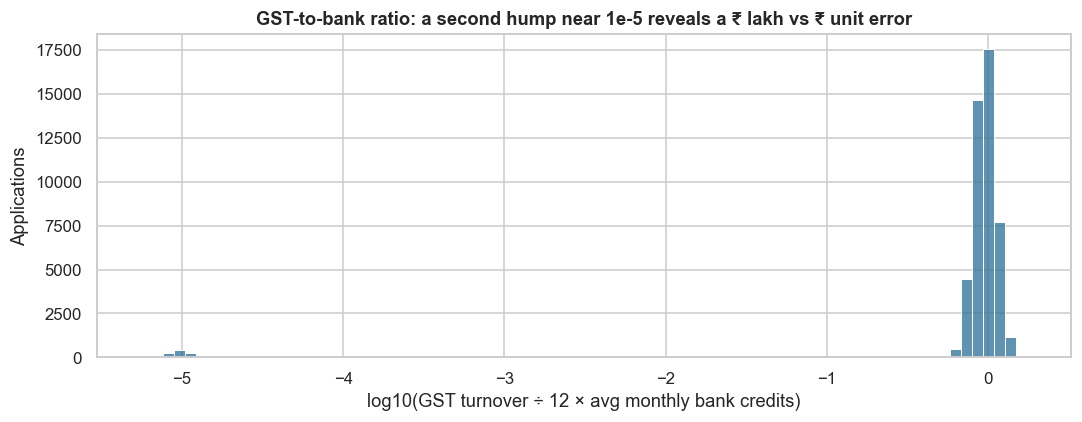

In [9]:
df["gst_to_bank_ratio"] = df.gst_turnover_12m_inr / (12 * df.avg_monthly_credits_inr)
ratio_check = (df.dropna(subset=["gst_to_bank_ratio"])
                 .assign(month=lambda d: d.application_date.dt.to_period("M"))
                 .groupby(["source_channel", "month"]).gst_to_bank_ratio.median().unstack(0))
suspect = ratio_check[ratio_check.lt(0.01).any(axis=1)]
print("Months where some channel's median GST/bank ratio is below 0.01:")
print(suspect.round(5))

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(np.log10(df.gst_to_bank_ratio.dropna()), bins=80, ax=ax, color="#2a6f97")
ax.set_xlabel("log10(GST turnover ÷ 12 × avg monthly bank credits)"); ax.set_ylabel("Applications")
ax.set_title("GST-to-bank ratio: a second hump near 1e-5 reveals a ₹ lakh vs ₹ unit error")
plt.tight_layout(); plt.show()

**Takeaway:** almost every business has a GST-to-bank ratio near 1 (log₁₀ ≈ 0). A separate cluster sits around 10⁻⁵, which is exactly a ₹-lakh-vs-₹ factor of 100,000, and it comes only from **DSA_Partner_07 in Aug–Oct 2019**. This is a feed bug, not a business signal. **Fix:** multiply those values by 10⁵, and add an automated ratio check to the partner-onboarding QA.

In [10]:
bad_unit = (df.source_channel == "DSA_Partner_07") & df.application_date.between("2019-08-01", "2019-10-31") & (df.gst_to_bank_ratio < 0.01)
print(f"Rows fixed for GST unit error: {bad_unit.sum():,}")
df.loc[bad_unit, "gst_turnover_12m_inr"] *= 1e5

clean = (df.sort_values("application_date")
           .drop_duplicates("business_id", keep="first")        # first application = the one whose performance we track
           .copy())
clean["vintage_unknown"] = (clean.vintage_years == 99).astype(int)
clean.loc[clean.vintage_years == 99, "vintage_years"] = np.nan
clean.loc[clean.bureau_score == 0, "bureau_score"] = np.nan
clean["ntc"] = clean.bureau_score.isna().astype(int)              # new-to-credit flag
clean["period"] = np.where(clean.application_date >= "2020-04-01", "OOT", "DEV")
clean = clean.drop(columns=["gst_to_bank_ratio"]).reset_index(drop=True)
out_of_window = (~clean.application_date.between("2019-04-01", "2021-03-31")).sum()
print(f"Out-of-window dates after de-duplication: {out_of_window} "
      f"(all {checks['application_date outside Apr-2019..Mar-2021']} raw cases were re-application copies dated after Mar-2021)")
assert out_of_window == 0
clean.to_csv("data/case2_msme_applications_clean.csv", index=False)

dq_log = pd.DataFrame([
    ("Re-applications (same business within 60 days)", checks["re-applications (duplicate business_id)"], "Keep first application", "One row per business; the outcome belongs to the first loan. Keeping both would double-count and leak across splits"),
    ("Dates after Mar-2021", checks["application_date outside Apr-2019..Mar-2021"], "Removed by de-duplication (all were re-application copies)", "Date-range check re-run after cleaning: 0 remain"),
    ("GST turnover in ₹ lakh (DSA_Partner_07, Aug–Oct 2019)", int(bad_unit.sum()), "Multiply by 10⁵", "Unit error confirmed by the GST/bank ratio ≈ 10⁻⁵ vs ≈ 1 elsewhere"),
    ("vintage_years = 99", checks["vintage_years = 99 (sentinel 'unknown')"], "Set missing → train-median impute + flag", "Sentinel, not a 99-year-old business"),
    ("bureau_score = 0", checks["bureau_score = 0 (no-hit coded as zero)"], "Set missing → treat as new-to-credit", "System default for 'no hit'; same meaning as blank"),
    ("bureau_score blank (NTC)", int(df.bureau_score.isna().sum()), "Keep as own WoE bin; NTC flag + impute 700 in logistic", "Missingness is informative (younger, thinner-file firms)"),
    ("GST fields blank", int(df.gst_turnover_12m_inr.isna().sum()), "Structural: gst_registered flag + impute", "Not registered ≠ missing data"),
    ("Trend/momentum blank (parser)", int(df.balance_trend_pct.isna().sum()), "Train-median impute + Missing WoE bin", "Random failures (1.5%); dropping would bias towards clean statements"),
    ("Heavy right tails (₹ amounts, EMI/ADB)", "all", "log₂ transform; cap ratios/counts at train 1st/99th pct", "Outliers are genuine (big businesses) but must not dominate the logistic fit"),
], columns=["issue", "rows", "treatment", "reason"])
print(f"Clean dataset: {len(clean):,} businesses | DEV {clean.period.eq('DEV').sum():,} | OOT {clean.period.eq('OOT').sum():,}")
dq_log

Rows fixed for GST unit error: 1,009
Out-of-window dates after de-duplication: 0 (all 47 raw cases were re-application copies dated after Mar-2021)


Clean dataset: 50,000 businesses | DEV 28,604 | OOT 21,396


,issue,rows,treatment,reason
0,Re-applications (same business within 60 days),1000,Keep first application,One row per business; the outcome belongs to t...
1,Dates after Mar-2021,47,Removed by de-duplication (all were re-applica...,Date-range check re-run after cleaning: 0 remain
2,"GST turnover in ₹ lakh (DSA_Partner_07, Aug–Oc...",1009,Multiply by 10⁵,Unit error confirmed by the GST/bank ratio ≈ 1...
3,vintage_years = 99,30,Set missing → train-median impute + flag,"Sentinel, not a 99-year-old business"
4,bureau_score = 0,42,Set missing → treat as new-to-credit,System default for 'no hit'; same meaning as b...
5,bureau_score blank (NTC),5569,Keep as own WoE bin; NTC flag + impute 700 in ...,"Missingness is informative (younger, thinner-f..."
6,GST fields blank,3944,Structural: gst_registered flag + impute,Not registered ≠ missing data
7,Trend/momentum blank (parser),757,Train-median impute + Missing WoE bin,Random failures (1.5%); dropping would bias to...
8,"Heavy right tails (₹ amounts, EMI/ADB)",all,log₂ transform; cap ratios/counts at train 1st...,Outliers are genuine (big businesses) but must...


### 5.1 Split design: train / test / out-of-time

- **Observation window:** the 12 months of bank statements and GST before the application. All features are frozen at the application date, so there is no future information.
- **Performance window:** 12 months after disbursal. Target = ever 90+ DPD. For the OOT period, the RBI moratorium (Mar–Aug 2020) froze DPD counting. In production we would extend the performance window by the moratorium months (D-2-08). The synthetic data is generated as if this was already done.
- **Development (DEV):** applications Apr 2019 – Mar 2020, split **70% train / 30% test**, stratified on the target, seed 42.
- **Out-of-time (OOT):** applications Apr 2020 – Mar 2021, the shock period. This is never used for fitting.

In [11]:
dev = clean[clean.period == "DEV"]; oot = clean[clean.period == "OOT"].copy()
train, test = train_test_split(dev, test_size=0.30, stratify=dev.default_90dpd_12m, random_state=SEED)
train, test = train.copy(), test.copy()
split = pd.DataFrame({s: [len(d), d.default_90dpd_12m.sum(), d.default_90dpd_12m.mean()] for s, d in
                      [("train", train), ("test", test), ("OOT", oot)]}, index=["applications", "defaults", "default rate"]).T
split

,applications,defaults,default rate
train,"20,022.0000","1,342.0000",0.0670
test,"8,582.0000",575.0000,0.0670
OOT,"21,396.0000","2,151.0000",0.1005


## 6. Exploratory Data Analysis

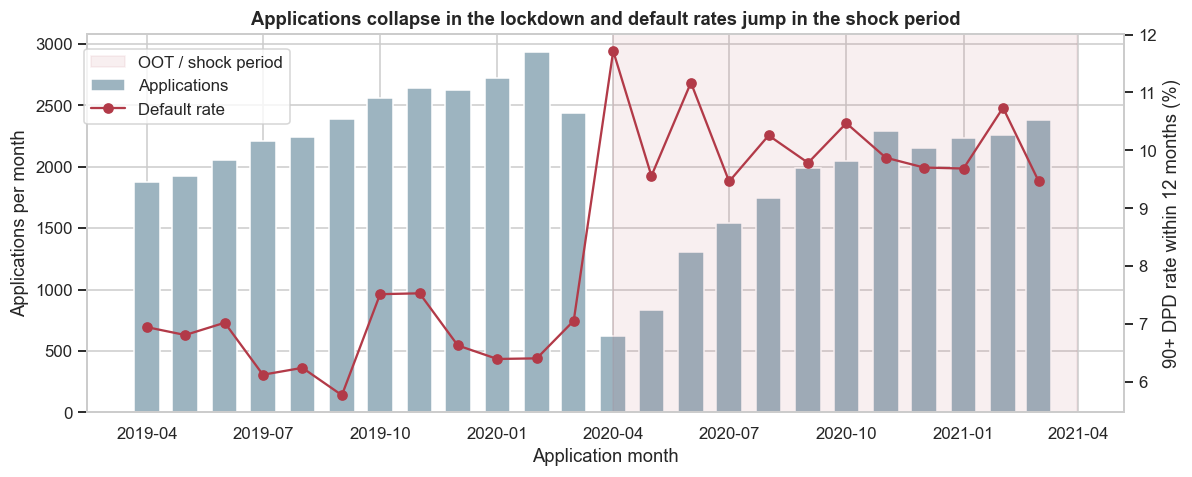

In [12]:
m = clean.assign(month=clean.application_date.dt.to_period("M").dt.to_timestamp()).groupby("month").agg(
    apps=("default_90dpd_12m", "size"), dr=("default_90dpd_12m", "mean"))
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(m.index, m.apps, width=20, color="#9db4c0", label="Applications")
ax1.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2021-03-31"), color="#b23a48", alpha=0.08, label="OOT / shock period")
ax1.set_xlabel("Application month"); ax1.set_ylabel("Applications per month")
ax2 = ax1.twinx(); ax2.plot(m.index, m.dr * 100, "o-", color="#b23a48", label="Default rate"); ax2.set_ylabel("90+ DPD rate within 12 months (%)"); ax2.grid(False)
ax1.set_title("Applications collapse in the lockdown and default rates jump in the shock period")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9)); plt.tight_layout(); plt.show()

**Takeaway:** applications fall by about 75% in April–May 2020 (lockdown). Loans written during the shock default at about **10%, against about 7% before it**. A model trained only on pre-shock data will face a riskier world than the one it learned from.

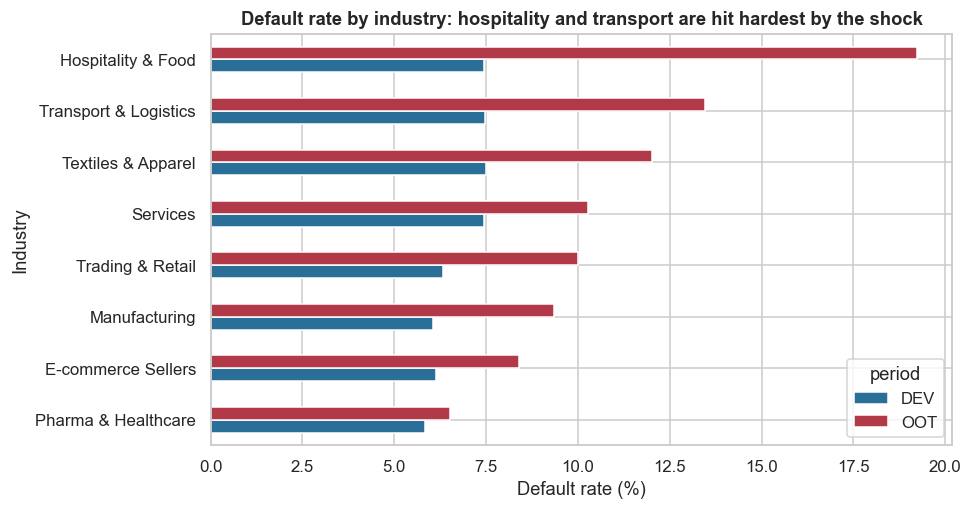

In [13]:
ind = clean.groupby(["industry", "period"]).default_90dpd_12m.mean().unstack().mul(100).sort_values("OOT")
ax = ind.plot(kind="barh", color={"DEV": "#2a6f97", "OOT": "#b23a48"}, figsize=(9, 4.8))
ax.set_xlabel("Default rate (%)"); ax.set_ylabel("Industry")
ax.set_title("Default rate by industry: hospitality and transport are hit hardest by the shock")
plt.tight_layout(); plt.show()

**Takeaway:** before the shock, industries differ by only a few points. During the shock, **hospitality & food more than doubles** (to about 20%+) and transport and textiles jump. Pharma and e-commerce barely move. An industry-blind cut-off would under-price exactly the sectors COVID hurt.

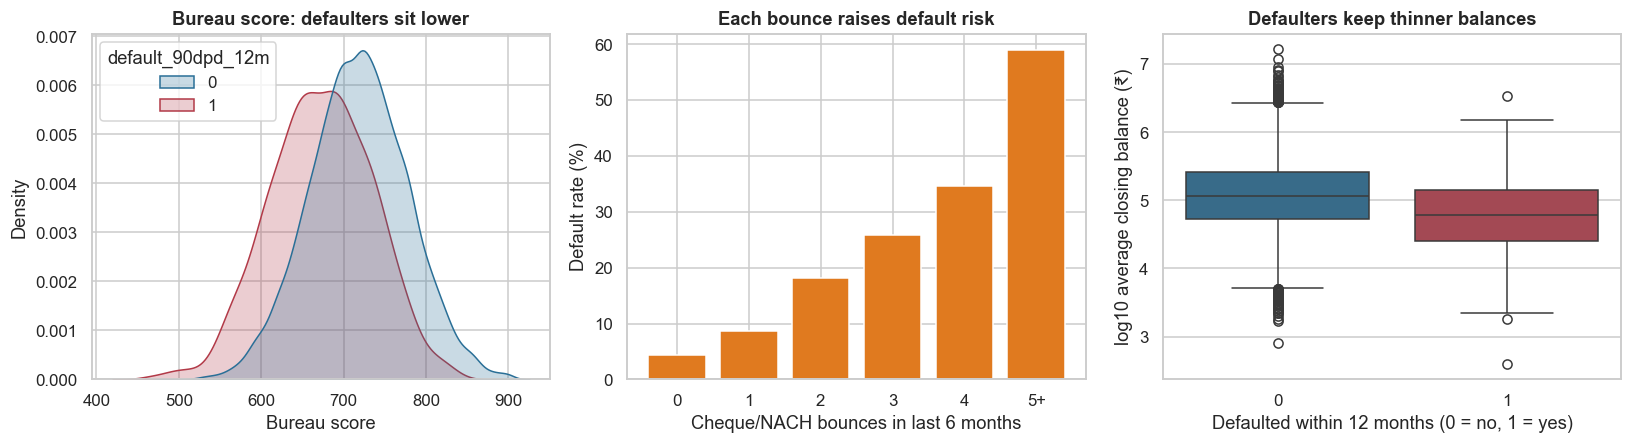

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.kdeplot(data=train.dropna(subset=["bureau_score"]), x="bureau_score", hue="default_90dpd_12m", common_norm=False, fill=True, ax=axes[0], palette=["#2a6f97", "#b23a48"])
axes[0].set_xlabel("Bureau score"); axes[0].set_ylabel("Density"); axes[0].set_title("Bureau score: defaulters sit lower")
b = train.assign(bounces=train.cheque_bounces_6m.clip(upper=5)).groupby("bounces").default_90dpd_12m.mean() * 100
axes[1].bar(b.index.astype(str).str.replace("5", "5+"), b.values, color="#e07a1f")
axes[1].set_xlabel("Cheque/NACH bounces in last 6 months"); axes[1].set_ylabel("Default rate (%)"); axes[1].set_title("Each bounce raises default risk")
sns.boxplot(data=train, x="default_90dpd_12m", y=np.log10(train.avg_closing_balance_inr), ax=axes[2], hue="default_90dpd_12m", palette=["#2a6f97", "#b23a48"], legend=False)
axes[2].set_xlabel("Defaulted within 12 months (0 = no, 1 = yes)"); axes[2].set_ylabel("log10 average closing balance (₹)"); axes[2].set_title("Defaulters keep thinner balances")
plt.tight_layout(); plt.show()

**Takeaway:** three intuitive signals line up. Defaulters have **lower bureau scores** (left). **Default risk climbs steeply with every cheque bounce** (centre: from about 4–5% with no bounces to well above 20% with 5 or more). And defaulters keep **thinner bank balances** (right). The curves overlap heavily, though: no single signal separates good from bad on its own, which is why we combine them in a model. Also note the **class imbalance**: only about 7 in 100 borrowers default, so accuracy is a useless metric (a model that approves everyone is "93% accurate"). We use KS, AUC and bad-rate tables instead.

## 7. Statistical Analysis (core section)

All feature analysis below uses the **train** sample only, so test and OOT remain untouched for honest evaluation. Each test follows the template **(a) why, (b) assumptions, (c) result + effect size + CI, (d) power, (e) multiple-testing, (f) business meaning.**

### 7.1 Model-ready features (transformations fixed on train)

**Business view:** money amounts are extremely skewed (a few businesses have 100× the median balance). We therefore work in **log₂(₹)**, so a coefficient reads as "*per doubling* of balance". Counts and ratios are capped at the train 1st/99th percentiles. Missing values are imputed with train medians, with a flag kept wherever missingness carries meaning (D-2-09).

In [15]:
NUM_RAW = ["vintage_years", "loan_amount_inr", "bureau_score", "bureau_enquiries_6m", "avg_monthly_credits_inr", "max_monthly_credit_inr",
           "credit_months_active", "avg_closing_balance_inr", "min_closing_balance_inr", "balance_trend_pct", "credit_trend_pct",
           "credit_growth_qoq_pct", "credit_growth_hoh_pct", "credit_growth_yoy_pct", "cheque_bounces_6m", "credit_declines_6m",
           "emi_to_adb", "gst_turnover_12m_inr", "gst_filing_ontime_pct"]
CAT = ["industry", "city_tier", "constitution", "source_channel"]
FLAGS = ["ntc", "gst_registered", "vintage_unknown"]
caps = {c: train[c].quantile([0.01, 0.99]).values for c in ["bureau_enquiries_6m", "balance_trend_pct", "credit_trend_pct", "credit_growth_qoq_pct",
                                                            "credit_growth_hoh_pct", "credit_growth_yoy_pct", "cheque_bounces_6m", "credit_declines_6m", "emi_to_adb"]}
med = train[NUM_RAW].median()

def prepare(d):
    """Model-ready features using TRAIN-fitted caps and medians (no leakage)."""
    x = pd.DataFrame(index=d.index)
    c = lambda col: d[col].clip(*caps[col]) if col in caps else d[col]
    x["bureau_50"] = (d.bureau_score.fillna(700) - 700) / 50                 # per 50 points, NTC imputed at 700
    x["ntc"] = d.ntc
    x["log2_vintage"] = np.log2(d.vintage_years.fillna(med.vintage_years))
    x["log2_loan"] = np.log2(d.loan_amount_inr)
    x["log2_credits"] = np.log2(d.avg_monthly_credits_inr)
    x["log2_max_credit"] = np.log2(d.max_monthly_credit_inr)
    x["log2_avg_bal"] = np.log2(d.avg_closing_balance_inr)
    x["log2_min_bal"] = np.log2(d.min_closing_balance_inr + 1000)
    x["credit_months_active"] = d.credit_months_active
    x["bal_trend"] = c("balance_trend_pct").fillna(med.balance_trend_pct)
    x["credit_trend"] = c("credit_trend_pct").fillna(med.credit_trend_pct)
    x["qoq_10"] = c("credit_growth_qoq_pct").fillna(med.credit_growth_qoq_pct) / 10
    x["hoh_10"] = c("credit_growth_hoh_pct").fillna(med.credit_growth_hoh_pct) / 10
    x["yoy_10"] = c("credit_growth_yoy_pct").fillna(med.credit_growth_yoy_pct) / 10
    x["cheque_bounces"] = c("cheque_bounces_6m")
    x["credit_declines"] = c("credit_declines_6m")
    x["enquiries"] = c("bureau_enquiries_6m")
    x["log2_emi_adb"] = np.log2(c("emi_to_adb"))
    x["gst_registered"] = d.gst_registered
    x["log2_gst"] = np.log2(d.gst_turnover_12m_inr.fillna(12 * d.avg_monthly_credits_inr))   # unregistered: bank proxy
    x["gst_ontime_10"] = d.gst_filing_ontime_pct.fillna(med.gst_filing_ontime_pct) / 10
    return x

Xtr, Xte, Xoot = prepare(train), prepare(test), prepare(oot)
ytr, yte, yoot = train.default_90dpd_12m, test.default_90dpd_12m, oot.default_90dpd_12m
NUM = list(Xtr.columns)
print(f"{len(NUM)} candidate numeric features + {len(CAT)} categorical")
Xtr.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

21 candidate numeric features + 4 categorical


,mean,std,min,50%,max
bureau_50,0.2700,1.1500,-4.7000,0.1200,4.0000
ntc,0.1100,0.3100,0.0000,0.0000,1.0000
log2_vintage,2.3300,0.8700,0.0000,2.3200,5.3200
log2_loan,19.4900,1.3700,16.6100,19.5100,22.2500
log2_credits,19.2600,1.3100,13.4400,19.2600,24.1900
log2_max_credit,20.2200,1.3300,14.3400,20.2100,25.6600
log2_avg_bal,16.7900,1.7100,8.6400,16.7800,23.9600
log2_min_bal,14.9500,1.8400,9.9700,14.9000,23.0000
credit_months_active,11.3400,0.9300,3.0000,12.0000,12.0000
bal_trend,0.5300,3.1000,-6.8300,0.5400,7.7800


### 7.2 Correlation (Pearson and Spearman) and multicollinearity (VIF)

**(a) Why:** the brief asks for deliberately correlated features, and real bank-statement data is full of them: average balance vs minimum balance, bank credits vs GST turnover, QoQ vs HoH vs YoY growth. Highly correlated inputs make logistic coefficients unstable. Signs can even flip, so the CRO could not trust "what drives risk".
- **Pearson r** measures *linear* association. **Spearman ρ** measures *monotonic* association on ranks, which is robust to skew and outliers. We show both: when they disagree, the relationship is non-linear or outlier-driven.
- The **variance inflation factor (VIF)** says how much a coefficient's variance is inflated because the feature can be predicted from the others. VIF = 1/(1 − R²ⱼ). VIF > 5 is our cut-off (> 10 is severe).
**(b) Assumptions:** VIF assumes a linear model in the features as entered. That holds here, because these exact transformed features enter the logistic model.
**Rule (D-2-10):** while any VIF > 5, drop the high-VIF feature with the *lowest Information Value*, so we keep the most predictive member of each correlated group.

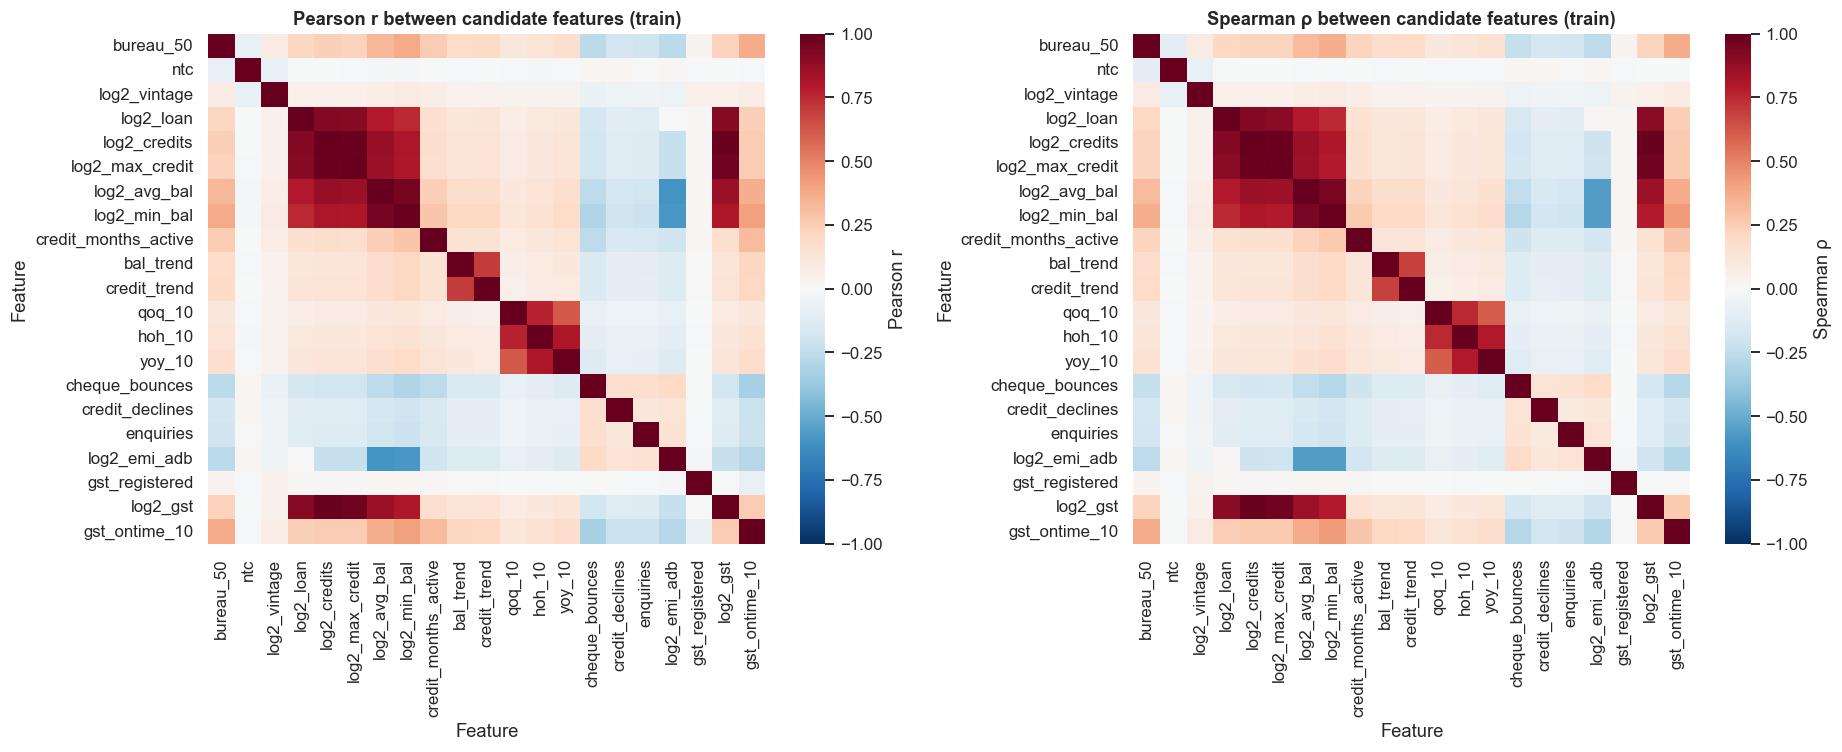

Feature pairs with |r| or |ρ| > 0.7:
                                 pearson  spearman
log2_credits    log2_max_credit   0.9880    0.9870
                log2_gst          0.9880    0.9870
log2_max_credit log2_gst          0.9760    0.9740
log2_avg_bal    log2_min_bal      0.9540    0.9510
log2_loan       log2_credits      0.9170    0.9150
                log2_max_credit   0.9070    0.9040
                log2_gst          0.9060    0.9030
log2_credits    log2_avg_bal      0.8750    0.8650
log2_max_credit log2_avg_bal      0.8640    0.8530
log2_avg_bal    log2_gst          0.8640    0.8530
log2_credits    log2_min_bal      0.8190    0.8070
hoh_10          yoy_10            0.8120    0.8000
log2_max_credit log2_min_bal      0.8090    0.7970
log2_min_bal    log2_gst          0.8080    0.7960
log2_loan       log2_avg_bal      0.8030    0.7940
qoq_10          hoh_10            0.7670    0.7530
log2_loan       log2_min_bal      0.7530    0.7440


In [16]:
pear = Xtr.corr(method="pearson"); spear = Xtr.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, cm, name in [(axes[0], pear, "Pearson r"), (axes[1], spear, "Spearman ρ")]:
    sns.heatmap(cm, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": name}, xticklabels=True, yticklabels=True)
    ax.set_title(f"{name} between candidate features (train)"); ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()
pairs = (pear.where(np.triu(np.ones(pear.shape, bool), 1)).stack().rename("pearson").to_frame()
           .join(spear.where(np.triu(np.ones(spear.shape, bool), 1)).stack().rename("spearman")))
pairs = pairs[pairs.pearson.abs().gt(0.7) | pairs.spearman.abs().gt(0.7)].sort_values("pearson", key=abs, ascending=False)
print("Feature pairs with |r| or |ρ| > 0.7:"); print(pairs.round(3))

**Takeaway:** the red blocks are the built-in correlated families: the four money-size features (credits, max credit, GST turnover, loan), average and minimum balance, and the three growth windows. Pearson and Spearman agree closely, so these are genuine, monotonic relationships, not artefacts of outliers. Each block should be represented by **one** feature in the scorecard, not all of them.

In [17]:
iv_tr_num = iv_summary(Xtr.assign(y=ytr.values), NUM, "y").set_index("feature").IV

def vif_table(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns)

kept, log = list(NUM), []
while True:
    v = vif_table(Xtr[kept])
    if v.max() <= 5:
        break
    high = v[v > 5].index
    drop = iv_tr_num[high].idxmin()
    log.append((drop, round(v[drop], 1), round(iv_tr_num[drop], 4), ", ".join(f"{h}" for h in high)))
    kept.remove(drop)
vif_log = pd.DataFrame(log, columns=["dropped", "its VIF", "its IV", "features with VIF > 5 at that step"])
print("Step-wise VIF reduction (drop lowest-IV member of the high-VIF group):"); print(vif_log.to_string(index=False))
print("\nFinal VIFs (all <= 5):"); print(vif_table(Xtr[kept]).round(2).sort_values(ascending=False).to_string())

Step-wise VIF reduction (drop lowest-IV member of the high-VIF group):
        dropped  its VIF  its IV                                                           features with VIF > 5 at that step
      log2_loan 399.9000  0.1713 log2_loan, log2_credits, log2_max_credit, log2_avg_bal, log2_min_bal, log2_emi_adb, log2_gst
       log2_gst  42.0000  0.1893                          log2_credits, log2_max_credit, log2_avg_bal, log2_min_bal, log2_gst
   log2_credits  51.8000  0.1937                                    log2_credits, log2_max_credit, log2_avg_bal, log2_min_bal
log2_max_credit   8.0000  0.1969                                                  log2_max_credit, log2_avg_bal, log2_min_bal
   log2_avg_bal  11.8000  0.3522                                                                   log2_avg_bal, log2_min_bal

Final VIFs (all <= 5):


hoh_10                 4.3600
yoy_10                 3.0000
qoq_10                 2.4300
bal_trend              1.9900
credit_trend           1.9800
log2_min_bal           1.8400
log2_emi_adb           1.5300
gst_ontime_10          1.4500
bureau_50              1.3200
cheque_bounces         1.2200
credit_months_active   1.2000
enquiries              1.1000
credit_declines        1.0900
log2_vintage           1.0200
ntc                    1.0200
gst_registered         1.0100


**(f) What this means for the business:** the VIF procedure removed five features, each time keeping the stronger member of a correlated family:
- **Loan amount** (VIF ≈ 400): it is almost exactly predictable from balance and EMI/ADB, because EMI/ADB = EMI ÷ balance.
- **GST turnover, bank credits and maximum monthly credit**: the "money-size" family, with r ≈ 0.99 between each pair.
- **Average closing balance** (r = 0.94 with minimum balance). Minimum balance has the higher IV (0.45 vs 0.35) and is the sharper "cash-stress" signal, so it stays.

After this, every VIF is ≤ 4.4. **For the business:** GST turnover and bank credits tell the same story, so once we have one, the other adds no new *scoring* information. GST data is still essential for **verification**: it is what caught the partner unit error in Section 5, and in production it flags turnover inflation and circular transactions.

### 7.3 Categorical signals: chi-square test of independence + Cramér's V

**(a) Why:** industry, tier, constitution, channel and the GST/NTC flags are categories. The chi-square test asks whether default rates differ across levels more than chance allows. **Cramér's V** (0 = no association, 1 = perfect) measures strength, independent of sample size. **(b) Assumptions:** independent businesses (ensured by de-duplication); expected count ≥ 5 in every cell (checked below). **Where a 2×2 table has an expected count below 5, the chi-square approximation is unreliable, so we automatically switch to Fisher's exact test** (D-2-12). **(e)** Holm correction across the 7 tests.

In [18]:
def chi2_v(x, y):
    tab = pd.crosstab(x, y)
    chi2, p, dof, exp = stats.chi2_contingency(tab, correction=False)
    test_used = "chi-square"
    if exp.min() < 5 and tab.shape == (2, 2):
        p = stats.fisher_exact(tab.values)[1]; test_used = "Fisher exact (expected < 5)"
    return chi2, dof, p, np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))), exp.min(), test_used
rows = []
for col in CAT + ["gst_registered", "ntc", "vintage_unknown"]:
    chi2, dof, p, v, emin, used = chi2_v(train[col], ytr)
    rates = train.groupby(col).default_90dpd_12m.mean()
    rows.append((col, used, chi2, dof, p, v, emin, f"{rates.idxmin()} {rates.min():.1%} → {rates.idxmax()} {rates.max():.1%}"))
cat_tests = pd.DataFrame(rows, columns=["feature", "test used", "chi2", "dof", "p_value", "cramers_V", "min_expected", "lowest → highest default rate"])
cat_tests["p_holm"] = multipletests(cat_tests.p_value, method="holm")[1]
cat_tests["significant (Holm)"] = cat_tests.p_holm < 0.05
cat_tests.sort_values("cramers_V", ascending=False)

,feature,test used,chi2,dof,p_value,cramers_V,min_expected,lowest → highest default rate,p_holm,significant (Holm)
1,city_tier,chi-square,66.9691,2,0.0000,0.0578,332.3163,Tier 1 5.5% → Tier 3 9.2%,0.0000,True
4,gst_registered,chi-square,16.9858,1,0.0000,0.0291,103.1534,1 6.5% → 0 9.2%,0.0002,True
5,ntc,chi-square,13.6530,1,0.0002,0.0261,148.9324,0 6.5% → 1 8.6%,0.0011,True
0,industry,chi-square,13.2894,7,0.0654,0.0258,79.4932,E-commerce Sellers 5.9% → Textiles & Apparel 7.9%,0.2615,False
3,source_channel,chi-square,5.8264,4,0.2125,0.0171,194.9794,Mobile App 6.3% → DSA_Partner_03 7.4%,0.6375,False
2,constitution,chi-square,2.4024,2,0.3008,0.0110,203.0896,Private Ltd 6.3% → Proprietorship 6.9%,0.6375,False
6,vintage_unknown,Fisher exact (expected < 5),0.0511,1,0.5652,0.0016,0.8043,0 6.7% → 1 8.3%,0.6375,False


**(f) What this means for the business:** - **City tier is the strongest categorical signal** (Tier 1 5.5% → Tier 3 9.2%, V = 0.058). **GST registration** (unregistered 9.2% vs 6.5%) and **new-to-credit status** (8.6% vs 6.5%) also matter. All three survive Holm.
- **Industry, channel and constitution are not significant pre-shock** (Holm p ≥ 0.26). In normal times, sector barely matters once you know the cash flows. Keep this in mind: Section 7.8 shows that during the shock, industry suddenly matters a lot.
- `vintage_unknown` had a minimum expected count of 0.8, so the chi-square was automatically replaced by **Fisher's exact test** (p = 0.57, not significant).
- All Cramér's V values are small (< 0.06). Categorical labels are weak on their own; the bank statement carries most of the signal.

**For the business:** the non-significant channel result is good news. DSA-sourced applicants are no riskier than direct ones, once the partner's GST unit error is fixed.

### 7.4 Numeric signals: Mann–Whitney U + rank-biserial correlation

**(a) Why not a t-test?** The t-test compares *means* and assumes roughly normal data. Our features are heavily skewed (₹ amounts, bounce counts with most values at zero), as the normality check below shows. The **Mann–Whitney U** test compares *ranks*: "if I pick one defaulter and one non-defaulter at random, is the defaulter's value systematically higher or lower?" It needs no normality and is robust to outliers (D-2-12).
**Effect size — rank-biserial correlation r_rb** = 2·(U / (n₁n₂)) − 1, running from −1 to +1. It equals P(defaulter > non-defaulter) − P(defaulter < non-defaulter). As a rule of thumb, |r| ≈ 0.1 is small, 0.3 medium and 0.5 large. Its link to AUC is direct: AUC of the single feature = (1 + |r_rb|)/2. The 95% CI comes from a bootstrap.
**(b) Assumptions:** independent observations, and similarly shaped distributions if we want to read it as a median shift (otherwise it tests stochastic dominance, which is the question we care about anyway).
**(d) Power:** with about 1,400 defaulters vs 18,600 non-defaulters in train, the power to detect even r_rb = 0.05 is above 95%. A non-significant result therefore means "truly negligible", not "under-powered".

In [19]:
RAW_TESTS = ["bureau_score", "cheque_bounces_6m", "credit_declines_6m", "avg_closing_balance_inr", "min_closing_balance_inr",
             "avg_monthly_credits_inr", "credit_months_active", "balance_trend_pct", "credit_growth_yoy_pct", "credit_growth_qoq_pct",
             "emi_to_adb", "gst_turnover_12m_inr", "gst_filing_ontime_pct", "vintage_years", "bureau_enquiries_6m", "loan_amount_inr"]
boot_rng = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
rows = []
for col in RAW_TESTS:
    a = train.loc[ytr == 1, col].dropna().values; b = train.loc[ytr == 0, col].dropna().values
    sw_p = stats.shapiro(boot_rng.choice(b, 500, replace=False)).pvalue
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * U / (len(a) * len(b)) - 1
    bs = []
    for _ in range(200):
        aa, bb = boot_rng.choice(a, len(a)), boot_rng.choice(b, 3000)
        bs.append(2 * stats.mannwhitneyu(aa, bb).statistic / (len(aa) * len(bb)) - 1)
    rows.append((col, stats.skew(b), sw_p, np.median(a), np.median(b), U, p, r, *np.percentile(bs, [2.5, 97.5])))
mw = pd.DataFrame(rows, columns=["feature", "skew (non-def.)", "Shapiro p (n=500)", "median defaulters", "median non-defaulters",
                                 "U", "p_value", "rank_biserial", "r_CI_low", "r_CI_high"])
mw["p_holm"] = multipletests(mw.p_value, method="holm")[1]
mw["significant (Holm)"] = mw.p_holm < 0.05
mw.sort_values("rank_biserial", key=abs, ascending=False).round(4)

,feature,skew (non-def.),Shapiro p (n=500),median defaulters,median non-defaulters,U,p_value,rank_biserial,r_CI_low,r_CI_high,p_holm,significant (Holm)
0,bureau_score,0.0055,0.9054,673.0000,718.0000,"5,767,043.5000",0.0000,-0.3986,-0.4320,-0.3684,0.0000,True
4,min_closing_balance_inr,15.8818,0.0000,"13,000.0000","31,200.0000","8,035,772.0000",0.0000,-0.3589,-0.3931,-0.3255,0.0000,True
12,gst_filing_ontime_pct,-1.1443,0.0000,69.1500,82.4000,"6,802,159.5000",0.0000,-0.3440,-0.3793,-0.3086,0.0000,True
3,avg_closing_balance_inr,9.7030,0.0000,"60,200.0000","117,200.0000","8,561,589.5000",0.0000,-0.3169,-0.3468,-0.2817,0.0000,True
1,cheque_bounces_6m,2.3523,0.0000,1.0000,0.0000,"16,419,653.0000",0.0000,0.3100,0.2769,0.3474,0.0000,True
8,credit_growth_yoy_pct,-0.0080,0.4364,-1.5000,8.7000,"8,929,607.0000",0.0000,-0.2692,-0.3007,-0.2298,0.0000,True
11,gst_turnover_12m_inr,4.3554,0.0000,"4,878,000.0000","7,324,000.0000","7,887,862.5000",0.0000,-0.2393,-0.2812,-0.2026,0.0000,True
10,emi_to_adb,2.9521,0.0000,0.4420,0.3290,"15,528,816.5000",0.0000,0.2389,0.2012,0.2761,0.0000,True
5,avg_monthly_credits_inr,4.2562,0.0000,"432,300.0000","640,400.0000","9,549,711.0000",0.0000,-0.2381,-0.2676,-0.2046,0.0000,True
6,credit_months_active,-1.7676,0.0000,11.0000,12.0000,"9,579,680.0000",0.0000,-0.2357,-0.2691,-0.2013,0.0000,True


**(f) What this means for the business:** - **Every one of the 16 numeric features differs significantly** between defaulters and non-defaulters after Holm (all p < 10⁻⁶). With 20,000 applications, "significant" alone cannot rank them, but **effect sizes** can.
- **Strongest** (|r_rb| 0.31–0.40, "medium"): bureau score (r = −0.40; median 673 vs 718), **minimum closing balance** (−0.36; ₹13,000 vs ₹31,200), **GST on-time filing** (−0.34; 69% vs 82%), average balance (−0.32) and **cheque bounces** (+0.31: the typical defaulter has 1 bounce in 6 months, the typical non-defaulter none).
- **Next**: YoY credit growth (−0.27; defaulters' inflows are *shrinking*, −1.5% vs +8.7%), GST turnover, EMI/ADB (+0.24) and credit months active. **Weakest**: business vintage (−0.13).
- **Assumption check:** Shapiro–Wilk rejects normality for every ₹, count and ratio feature (skew up to 16). A t-test on means would be dominated by a handful of very large businesses. Mann–Whitney is the right tool here.
- The bootstrap CIs are tight (about ±0.03), so the ranking of the top features is reliable.

**For the business:** the cash-flow signals (balances, bounces, GST discipline, growth) are nearly as strong as the bureau score itself. That is exactly why bank-statement underwriting can serve thin-file MSMEs that a bureau-only policy rejects.

### 7.5 Weight of Evidence and Information Value — feature selection

**(a) Why WoE/IV?** IV is the credit-industry standard for ranking features. It handles missing values as their own bin (crucial for new-to-credit applicants), captures non-linear patterns, and is easy to explain bin by bin. We compute IV on train for every candidate feature, raw categoricals included. **Selection rule (D-2-10):** keep IV ≥ 0.02; investigate IV > 0.5 for leakage; then apply the VIF filter from 7.2.

In [20]:
iv_all = iv_summary(Xtr.assign(**{c: train[c].values for c in CAT}, y=ytr.values), NUM + CAT, "y")
iv_all["passes VIF"] = iv_all.feature.isin(kept) | iv_all.feature.isin(CAT)
iv_all.round(4)

,feature,IV,strength,passes VIF
0,bureau_50,0.4672,strong,True
1,log2_min_bal,0.4482,strong,True
2,cheque_bounces,0.4397,strong,True
3,gst_ontime_10,0.3563,strong,True
4,log2_avg_bal,0.3522,strong,False
5,credit_months_active,0.2431,medium,True
6,yoy_10,0.2252,medium,True
7,credit_declines,0.2145,medium,True
8,log2_max_credit,0.1969,medium,False
9,log2_credits,0.1937,medium,False


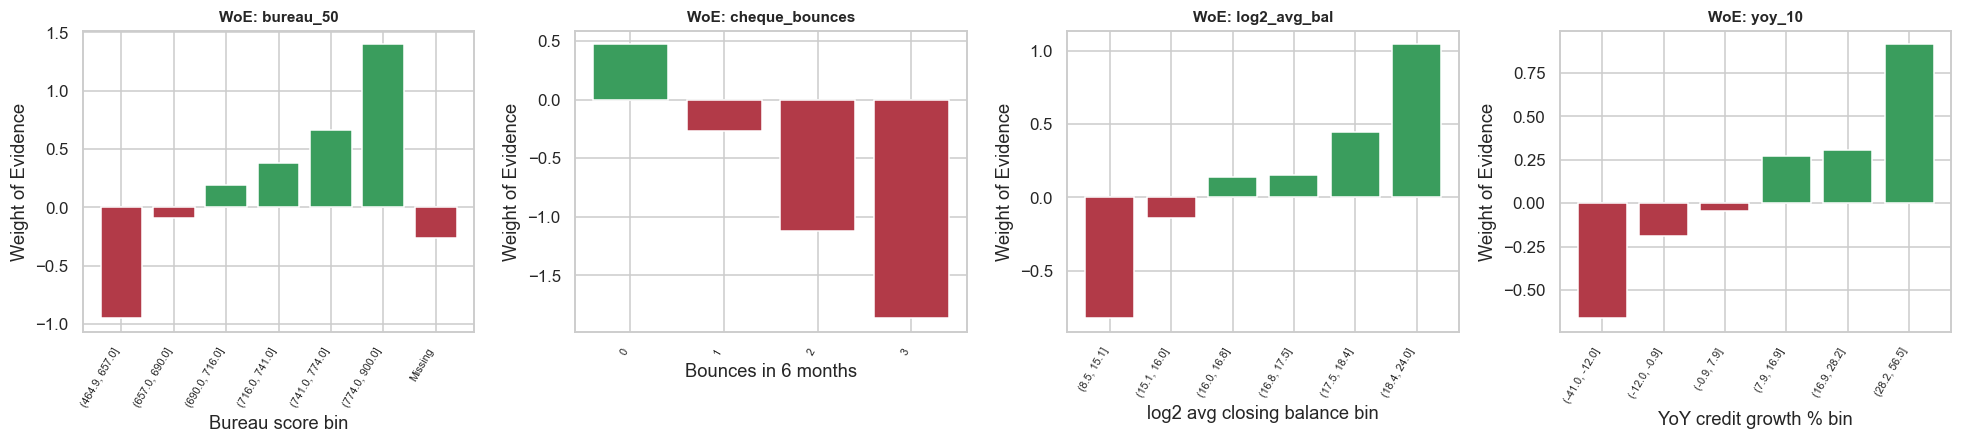

In [21]:
top4 = ["bureau_50", "cheque_bounces", "log2_avg_bal", "yoy_10"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
raw_map = {"bureau_50": train.bureau_score, "cheque_bounces": Xtr.cheque_bounces, "log2_avg_bal": Xtr.log2_avg_bal, "yoy_10": Xtr.yoy_10 * 10}
labels = {"bureau_50": "Bureau score bin", "cheque_bounces": "Bounces in 6 months", "log2_avg_bal": "log2 avg closing balance bin", "yoy_10": "YoY credit growth % bin"}
for ax, f in zip(axes, top4):
    t = woe_table(raw_map[f], ytr, bins=6 if f != "cheque_bounces" else 10)
    ax.bar(range(len(t)), t.WoE, color=np.where(t.WoE > 0, "#3a9d5d", "#b23a48"))
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=60, ha="right", fontsize=7)
    ax.set_xlabel(labels[f]); ax.set_ylabel("Weight of Evidence"); ax.set_title(f"WoE: {f}", fontsize=10)
plt.tight_layout(); plt.show()

**Takeaway:** all four top features have a clean, **monotonic** WoE pattern: risk falls steadily as bureau score, balance and growth rise, and rises with every bounce. Monotonic patterns are what a credit policy can defend to auditors and the regulator ("higher balance → lower risk, always"). For bureau score, the **Missing (new-to-credit) bin has negative WoE**: thin-file businesses are riskier than average but far from the worst. That is why we keep them as their own group instead of rejecting them outright.

**(f) What this means for the business:** - **Strong (IV 0.35–0.47):** bureau score, minimum balance, cheque bounces, GST on-time filing, and average balance (later removed by VIF in favour of minimum balance).
- **Medium (0.1–0.3):** credit months active, YoY growth, credit declines, EMI/ADB, the money-size family, HoH growth, enquiries, credit trend.
- **Weak (0.02–0.1):** balance trend, QoQ growth, vintage, city tier.
- **Useless (< 0.02, excluded):** GST-registered flag, industry, NTC flag, channel, constitution.
- **No feature exceeds IV 0.5**, so there is no leakage red flag. (The public German Credit check showed what a genuinely dominant feature looks like: checking status, IV 0.66.)
- The NTC flag on its own is "useless" (IV 0.01) because NTC businesses are only slightly riskier on average. Their information is already carried by the bureau variable's Missing bin.

**For the business:** the families documented by Lendingkart (aggregates, negative indicators, momentum, GST) all deliver real signal. After IV and VIF filtering, **14 numeric features plus city tier** go forward to the scorecard.

### 7.6 Logistic regression scorecard (statsmodels): coefficients, odds ratios, CIs, p-values

**(a) Why logistic regression?** It is the regulatory and industry standard for scorecards. Every coefficient has a direct business reading ("each extra bounce multiplies the odds of default by X"), it produces probabilities that can be calibrated, and it converts transparently into score points. An **odds ratio (OR)** > 1 means the feature raises risk; < 1 means it lowers risk.
**Feature set (D-2-13):** (1) start with every VIF-surviving numeric feature and every categorical with IV ≥ 0.02; (2) fit the full model; (3) **one backward pass**: drop numeric terms with Wald p > 0.05 and refit; (4) confirm with a **likelihood-ratio test** that the dropped terms, *jointly*, add nothing (p > 0.05). One pass, not repeated stepwise selection, because repeated stepwise selection over-fits and biases p-values.
**(b) Assumptions:** (1) independent observations (one row per business, ✓); (2) a linear relationship between each feature and the **log-odds**. The monotonic WoE plots and log₂ transforms support this; (3) no severe multicollinearity (VIF ≤ 5, ✓); (4) enough events per variable: ≈ 1,400 defaults / ≈ 25 parameters ≈ 55 events per parameter, well above the ≥ 10–20 rule of thumb.

In [22]:
iv_cat = iv_all.set_index("feature").IV
cand_feats = [f for f in kept if iv_tr_num[f] >= 0.02]
cat_in = [c for c in CAT if iv_cat[c] >= 0.02]
print("Numeric candidates (VIF ok, IV >= 0.02):", cand_feats)
print("Dropped for IV < 0.02:", [f for f in kept if iv_tr_num[f] < 0.02], "| categoricals kept:", cat_in, "| dropped:", [c for c in CAT if c not in cat_in])
def fit_logit(feats):
    f = "y ~ " + " + ".join(feats + [f"C({c})" for c in cat_in])
    return smf.logit(f, data=trd).fit(disp=0)
trd = Xtr.assign(y=ytr.values, **{c: train[c].values for c in CAT})
full = fit_logit(cand_feats)
nonsig = [f for f in cand_feats if full.pvalues[f] > 0.05]
model_feats = [f for f in cand_feats if f not in nonsig]
logit = fit_logit(model_feats)
lr_stat = 2 * (full.llf - logit.llf); lr_df = full.df_model - logit.df_model
print(f"\nBackward pass dropped (p > 0.05): {nonsig}")
print(f"LR test full vs reduced: LR = {lr_stat:.2f}, df = {lr_df:.0f}, p = {stats.chi2.sf(lr_stat, lr_df):.3f}  (p > 0.05 -> dropped terms add nothing jointly)")
print(f"AIC full = {full.aic:,.1f} | AIC reduced = {logit.aic:,.1f}")
ci = logit.conf_int()
coef_tab = pd.DataFrame({"coef": logit.params, "std_err": logit.bse, "z": logit.tvalues, "p_value": logit.pvalues,
                         "odds_ratio": np.exp(logit.params), "OR_CI_low": np.exp(ci[0]), "OR_CI_high": np.exp(ci[1])})
coef_tab.index = coef_tab.index.str.replace(r"C\((\w+)\)", r"\1", regex=True)
print(f"\nPseudo R² (McFadden) = {logit.prsquared:.3f} | LLR p-value = {logit.llr_pvalue:.3g} | n = {int(logit.nobs):,}")
coef_tab.round(4)

Numeric candidates (VIF ok, IV >= 0.02): ['bureau_50', 'log2_vintage', 'log2_min_bal', 'credit_months_active', 'bal_trend', 'credit_trend', 'qoq_10', 'hoh_10', 'yoy_10', 'cheque_bounces', 'credit_declines', 'enquiries', 'log2_emi_adb', 'gst_ontime_10']
Dropped for IV < 0.02: ['ntc', 'gst_registered'] | categoricals kept: ['city_tier'] | dropped: ['industry', 'constitution', 'source_channel']



Backward pass dropped (p > 0.05): ['bal_trend', 'credit_trend', 'qoq_10', 'hoh_10', 'log2_emi_adb', 'gst_ontime_10']
LR test full vs reduced: LR = 7.67, df = 6, p = 0.263  (p > 0.05 -> dropped terms add nothing jointly)
AIC full = 8,548.7 | AIC reduced = 8,544.4

Pseudo R² (McFadden) = 0.134 | LLR p-value = 3.22e-278 | n = 20,022


,coef,std_err,z,p_value,odds_ratio,OR_CI_low,OR_CI_high
Intercept,0.3453,0.4089,0.8444,0.3985,1.4124,0.6337,3.1478
city_tier[T.Tier 2],0.0465,0.0729,0.6384,0.5232,1.0476,0.9081,1.2086
city_tier[T.Tier 3],0.3872,0.0755,5.1309,0.0000,1.4729,1.2704,1.7077
bureau_50,-0.3164,0.0295,-10.7264,0.0000,0.7288,0.6878,0.7721
log2_vintage,-0.1685,0.0346,-4.8765,0.0000,0.8449,0.7896,0.9041
log2_min_bal,-0.1537,0.0197,-7.8080,0.0000,0.8576,0.8251,0.8913
credit_months_active,-0.0882,0.0276,-3.2007,0.0014,0.9155,0.8674,0.9664
yoy_10,-0.1427,0.0152,-9.3833,0.0000,0.8670,0.8415,0.8932
cheque_bounces,0.4071,0.0346,11.7778,0.0000,1.5024,1.4040,1.6077
credit_declines,0.2813,0.0375,7.5074,0.0000,1.3249,1.2311,1.4258


**Interpretation in plain English** (odds ratios; other factors held constant):

- **Model selection:** the backward pass removed 6 terms (balance trend, credit trend, QoQ, HoH, EMI/ADB, GST on-time filing). Jointly they add nothing (LR = 7.7 on 6 df, p = 0.26), and AIC improves (8,549 → 8,544). GST on-time filing was individually strong (IV 0.36), but once balances, bounces and bureau are in the model it carries no *extra* information.
- **Cheque bounces:** each additional bounce in 6 months **multiplies the odds of default by 1.50** (95% CI 1.40–1.61). This is the single most powerful behavioural red flag.
- **Credit declines:** each loan application rejected elsewhere in the last 6 months raises the odds by **32%** (OR 1.32; 1.23–1.43). **Enquiries:** +7% per enquiry ("credit hunger").
- **Bureau score:** every **+50 points cuts the odds by 27%** (OR 0.73; 0.69–0.77).
- **Minimum closing balance:** every **doubling** cuts the odds by **14%** (OR 0.86). A business that never runs its account dry is a safer borrower.
- **YoY credit growth:** every **+10 percentage points** of growth cuts the odds by **13%** (OR 0.87).
- **Credit months active:** each extra month with business inflows cuts the odds by 8%. **Vintage:** each doubling of business age (e.g., 3 → 6 years) cuts the odds by **16%** (OR 0.84).
- **City tier:** Tier 3 has **47% higher odds** than Tier 1 (OR 1.47; 1.27–1.71). Tier 2 is not different from Tier 1 (p = 0.52).
- McFadden pseudo-R² = 0.13, a typical value for credit models (it is not comparable with R² from linear regression). The model as a whole is overwhelmingly significant (LLR p ≈ 10⁻²⁷⁸).

Every sign matches business intuition, which is a requirement for regulatory model validation.

### 7.7 Discrimination: KS, Gini/AUC, and decile gains/lift (development test vs OOT)

**(a) Why these metrics?** They test whether the model *ranks* borrowers correctly, which is what a cut-off needs.
- **AUC** is the probability that a randomly chosen defaulter gets a higher PD than a randomly chosen non-defaulter (0.5 = coin flip, 1 = perfect). **Gini** = 2·AUC − 1, the form most Indian risk committees use.
- **KS** is the maximum separation between the cumulative distributions of bads and goods. In practice, it tells you how many more bads than goods you can reject at the best single cut-off.
- **The gains/lift table** sorts applicants into 10 equal groups by PD. **Lift** = the decile's bad rate ÷ the average bad rate.
**(d) Uncertainty:** 95% bootstrap CIs (500 resamples) for KS and AUC, because there is no simple closed-form CI for KS.

In [23]:
pd_tr = logit.predict(trd)
pd_te = logit.predict(Xte.assign(**{c: test[c].values for c in CAT}))
pd_oot = logit.predict(Xoot.assign(**{c: oot[c].values for c in CAT}))
boot_rng = np.random.default_rng(np.random.SeedSequence(SEED).spawn(2)[1])

def boot_ci(y, p, n=500):
    y, p = np.asarray(y), np.asarray(p); ks_, auc_ = [], []
    for _ in range(n):
        i = boot_rng.integers(0, len(y), len(y)); k, a, _g = ks_auc_gini(y[i], p[i]); ks_.append(k); auc_.append(a)
    return np.percentile(ks_, [2.5, 97.5]), np.percentile(auc_, [2.5, 97.5])

disc = []
for name, y, p in [("train", ytr, pd_tr), ("test (DEV)", yte, pd_te), ("OOT", yoot, pd_oot)]:
    k, a, g = ks_auc_gini(y, p); (klo, khi), (alo, ahi) = boot_ci(y, p)
    disc.append((name, len(y), y.mean(), k, klo, khi, a, alo, ahi, g))
disc = pd.DataFrame(disc, columns=["sample", "n", "bad rate", "KS", "KS_CI_low", "KS_CI_high", "AUC", "AUC_CI_low", "AUC_CI_high", "Gini"]).set_index("sample")
disc

,n,bad rate,KS,KS_CI_low,KS_CI_high,AUC,AUC_CI_low,AUC_CI_high,Gini
sample,,,,,,,,,
train,20022,0.0670,37.6568,35.8704,40.5178,0.7608,0.7485,0.7725,0.5215
test (DEV),8582,0.0670,39.3151,35.9869,43.5441,0.7617,0.7392,0.7822,0.5235
OOT,21396,0.1005,38.4875,36.5727,40.8424,0.7547,0.7438,0.7671,0.5095


In [24]:
def gains_table(y, p, bins=10):
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["decile"] = pd.qcut(d.p.rank(method="first", ascending=False), bins, labels=range(1, bins + 1))   # 1 = riskiest
    g = d.groupby("decile", observed=True).agg(n=("y", "size"), bads=("y", "sum"), min_PD=("p", "min"), max_PD=("p", "max"))
    g["bad_rate"] = g.bads / g.n
    g["cum_%bads"] = g.bads.cumsum() / g.bads.sum()
    g["cum_%goods"] = (g.n - g.bads).cumsum() / (g.n - g.bads).sum()
    g["KS"] = 100 * (g["cum_%bads"] - g["cum_%goods"])
    g["lift"] = g.bad_rate / d.y.mean()
    g["cum_lift"] = g["cum_%bads"] / (g.n.cumsum() / g.n.sum())
    return g
gt_test, gt_oot = gains_table(yte, pd_te), gains_table(yoot, pd_oot)
print("Gains table — DEV test (decile 1 = highest predicted risk)"); print(gt_test.round(3))
print("\nGains table — OOT"); print(gt_oot.round(3))

Gains table — DEV test (decile 1 = highest predicted risk)
          n  bads  min_PD  max_PD  bad_rate  cum_%bads  cum_%goods      KS   lift  cum_lift
decile                                                                                     
1       859   216  0.1480  0.8630    0.2510     0.3760      0.0800 29.5350 3.7530    3.7530
2       858    94  0.0970  0.1480    0.1100     0.5390      0.1760 36.3410 1.6350    2.6950
3       858    69  0.0700  0.0970    0.0800     0.6590      0.2740 38.4870 1.2000    2.1970
4       858    55  0.0540  0.0700    0.0640     0.7550      0.3750 38.0240 0.9570    1.8870
5       858    41  0.0430  0.0540    0.0480     0.8260      0.4770 34.9500 0.7130    1.6520
6       858    29  0.0340  0.0430    0.0340     0.8770      0.5800 29.6400 0.5040    1.4610
7       858    24  0.0270  0.0340    0.0280     0.9180      0.6840 23.3980 0.4170    1.3120
8       858    18  0.0210  0.0270    0.0210     0.9500      0.7890 16.0380 0.3130    1.1870
9       858    18  0.

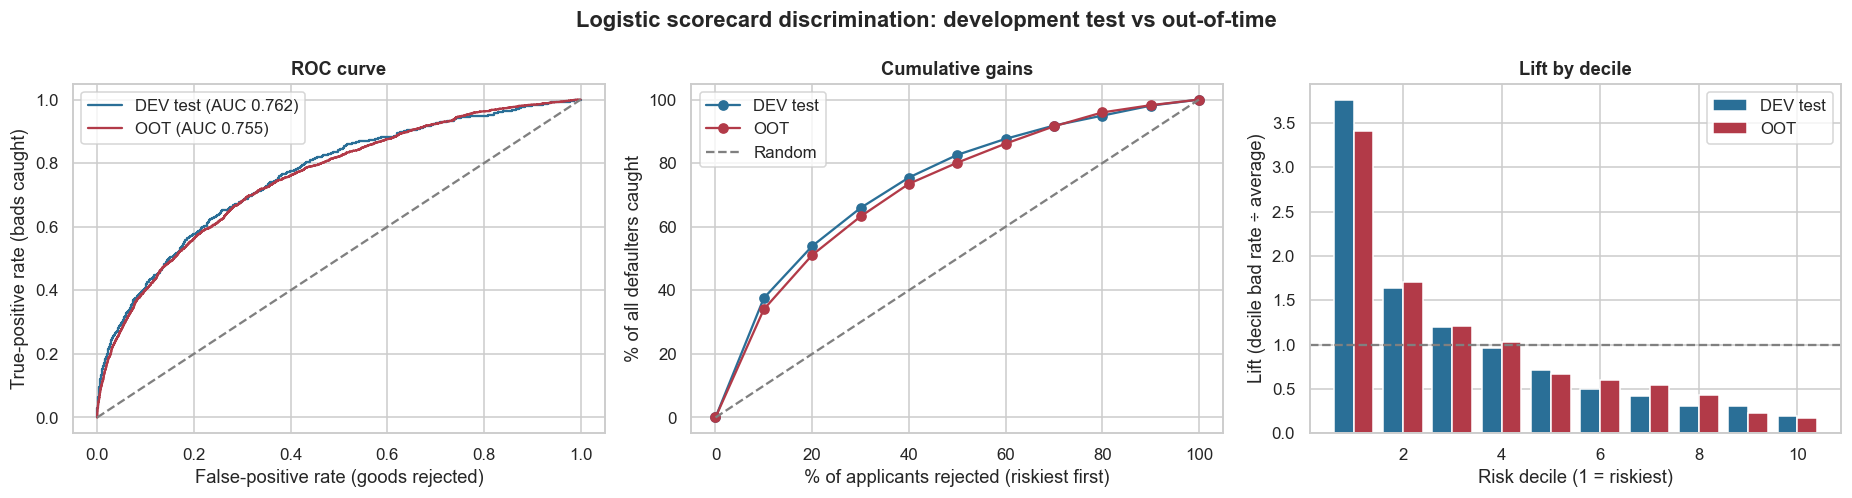

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for y, p, lab, c in [(yte, pd_te, "DEV test", "#2a6f97"), (yoot, pd_oot, "OOT", "#b23a48")]:
    fpr, tpr, _ = roc_curve(y, p); axes[0].plot(fpr, tpr, color=c, label=f"{lab} (AUC {roc_auc_score(y, p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey"); axes[0].set_xlabel("False-positive rate (goods rejected)"); axes[0].set_ylabel("True-positive rate (bads caught)")
axes[0].set_title("ROC curve"); axes[0].legend()
for g, lab, c in [(gt_test, "DEV test", "#2a6f97"), (gt_oot, "OOT", "#b23a48")]:
    axes[1].plot(np.r_[0, g.index.astype(int) * 10], np.r_[0, g["cum_%bads"] * 100], "o-", color=c, label=lab)
axes[1].plot([0, 100], [0, 100], "--", color="grey", label="Random")
axes[1].set_xlabel("% of applicants rejected (riskiest first)"); axes[1].set_ylabel("% of all defaulters caught"); axes[1].set_title("Cumulative gains"); axes[1].legend()
w = 0.4
axes[2].bar(gt_test.index.astype(int) - w / 2, gt_test.lift, w, color="#2a6f97", label="DEV test")
axes[2].bar(gt_oot.index.astype(int) + w / 2, gt_oot.lift, w, color="#b23a48", label="OOT")
axes[2].axhline(1, color="grey", ls="--"); axes[2].set_xlabel("Risk decile (1 = riskiest)"); axes[2].set_ylabel("Lift (decile bad rate ÷ average)")
axes[2].set_title("Lift by decile"); axes[2].legend()
plt.suptitle("Logistic scorecard discrimination: development test vs out-of-time", fontweight="bold"); plt.tight_layout(); plt.show()

**Takeaway:** - **Test KS = 39.3 (95% CI 36.0–43.5), AUC = 0.762, Gini = 0.52.** H0 (AUC = 0.5) is rejected decisively, and the result is comfortably above the acceptance band (KS ≥ 30).
- **No over-fitting:** train and test agree (KS 37.7 vs 39.3).
- **OOT KS = 38.5 (36.6–40.8), AUC = 0.755.** Rank-ordering survives the shock almost intact (KS falls by less than 1 point; the CIs overlap) and stays above the OOT band (≥ 25).
- **Gains:** rejecting the riskiest 10% of applicants removes **38% of all future defaulters** on test (34% OOT). The riskiest decile has **3.8×** the average bad rate. Rejecting the riskiest 30% removes **66%** of defaulters while turning away only 27% of good customers.

**For the CRO:** the model separates good from bad borrowers well, and keeps doing so in a shock. As the next two sections show, the issue in a shock is *how many* default (calibration and population), not *who* defaults (ranking).

### 7.8 Calibration: Hosmer–Lemeshow test and calibration plot

**(a) Why?** Discrimination says *who* is riskier. **Calibration** says whether a "5% PD" really defaults 5% of the time. Pricing, expected-loss provisioning (Ind AS 109 ECL) and the ₹ business case all need calibrated PDs.
**Hosmer–Lemeshow (HL):** sort by PD into 10 groups and compare observed vs expected defaults: HL = Σ (O − E)² / (E·(1 − E/n)), compared with χ²(8). A small p-value means miscalibration.
**(b) Caveat:** HL is very sensitive at large n (tiny, harmless deviations become "significant") and depends on the binning, so we always read it together with the plot.

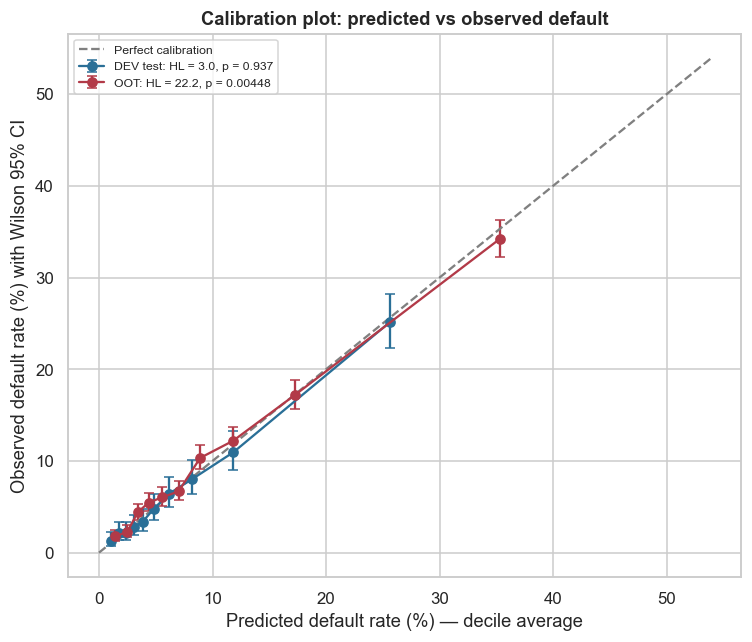

,observed default,mean predicted PD,HL statistic,dof,p_value
sample,,,,,
DEV test,0.0670,0.0688,2.9599,8,0.9368
OOT,0.1005,0.0976,22.2443,8,0.0045


In [26]:
def hosmer_lemeshow(y, p, g=10):
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["bin"] = pd.qcut(d.p, g, labels=False, duplicates="drop")
    t = d.groupby("bin").agg(n=("y", "size"), observed=("y", "sum"), expected=("p", "sum"))
    hl = (((t.observed - t.expected) ** 2) / (t.expected * (1 - t.expected / t.n))).sum()
    dof = len(t) - 2
    return hl, dof, stats.chi2.sf(hl, dof), t

cal = []
fig, ax = plt.subplots(figsize=(7, 6))
for y, p, lab, c in [(yte, pd_te, "DEV test", "#2a6f97"), (yoot, pd_oot, "OOT", "#b23a48")]:
    hl, dof, pv, t = hosmer_lemeshow(y, p)
    lo, hi = proportion_confint(t.observed, t.n, method="wilson")
    ax.errorbar(t.expected / t.n * 100, t.observed / t.n * 100, yerr=[(t.observed / t.n - lo) * 100, (hi - t.observed / t.n) * 100],
                fmt="o-", color=c, capsize=3, label=f"{lab}: HL = {hl:.1f}, p = {pv:.3g}")
    cal.append((lab, y.mean(), np.mean(p), hl, dof, pv))
mx = max(pd_te.max(), pd_oot.max()) * 100 * 0.6
ax.plot([0, mx], [0, mx], "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Predicted default rate (%) — decile average"); ax.set_ylabel("Observed default rate (%) with Wilson 95% CI")
ax.set_title("Calibration plot: predicted vs observed default"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
pd.DataFrame(cal, columns=["sample", "observed default", "mean predicted PD", "HL statistic", "dof", "p_value"]).set_index("sample")

**Takeaway:** - **DEV test:** predicted 6.9% vs actual 6.7%; HL = 3.0, p = 0.94. **Well calibrated**, and every decile sits on the diagonal within its CI.
- **OOT:** the overall average looks fine (9.8% predicted vs 10.05% actual), because the model "sees" the deteriorating cash flows and raises PDs. But **HL = 22.2, p = 0.005, so calibration is rejected.** The shock changed the relationship in some segments, and an overall average can hide that. The next table shows where.

**Calibration by segment (OOT).** An overall average can hide offsetting errors, so we compare predicted and actual default by industry in the shock period, with a binomial test for each industry (Holm-corrected).

In [27]:
seg_cal = []
for ind_, g in oot.assign(pd_=np.asarray(pd_oot)).groupby("industry"):
    pv = stats.binomtest(int(g.default_90dpd_12m.sum()), len(g), g.pd_.mean()).pvalue
    seg_cal.append((ind_, len(g), g.pd_.mean(), g.default_90dpd_12m.mean(), g.default_90dpd_12m.mean() / g.pd_.mean(), pv))
seg_cal = pd.DataFrame(seg_cal, columns=["industry", "n", "predicted PD", "actual default", "actual ÷ predicted", "binomial p"])
seg_cal["p_holm"] = multipletests(seg_cal["binomial p"], method="holm")[1]
seg_cal.sort_values("actual ÷ predicted", ascending=False).round(4)

,industry,n,predicted PD,actual default,actual ÷ predicted,binomial p,p_holm
1,Hospitality & Food,832,0.1190,0.1923,1.6154,0.0000,0.0000
7,Transport & Logistics,1108,0.1063,0.1345,1.2648,0.0034,0.0204
5,Textiles & Apparel,1715,0.1092,0.1201,1.1002,0.1518,0.6074
2,Manufacturing,3111,0.0882,0.0935,1.0609,0.2967,0.8900
4,Services,2801,0.0998,0.1028,1.0306,0.5919,0.9795
6,Trading & Retail,6494,0.0974,0.0999,1.0263,0.4898,0.9795
0,E-commerce Sellers,3232,0.0989,0.0838,0.8482,0.0039,0.0204
3,Pharma & Healthcare,2103,0.0846,0.0651,0.7704,0.0011,0.0079


**Takeaway (segment calibration):** the HL failure has a clear cause. **Hospitality & food defaults at 1.6× the predicted rate** (19.2% vs 11.9%) and **transport at 1.26×**, while **pharma (0.77×) and e-commerce (0.85×) default *less* than predicted**. These errors cancel out in the overall average. All four survive Holm.

This is **concept drift**. Pre-shock, industry carried no signal (IV 0.01, so it was excluded), so the model cannot know that hospitality became much riskier. **For the business:** expected-loss provisions and pricing for hospitality and transport loans written in the shock would be understated by about 25–60%. Pharma and e-commerce applicants are over-charged and partly turned away. **Fix:** a temporary industry overlay now, then recalibrate on post-shock vintages.

### 7.9 Stability: Population Stability Index (PSI) for the score and top features

**(a) Why PSI?** PSI measures how much a *distribution* has moved between a reference sample (DEV test) and a new one (OOT): PSI = Σ (actual% − expected%) · ln(actual% / expected%) over the reference deciles. It needs no outcomes, so it is the **early-warning** test we can run from day 1, before any defaults have matured. For individual features it is often called CSI (characteristic stability index). **Thresholds (D-2-11):** < 0.10 stable · 0.10–0.25 moderate shift, monitor · > 0.25 significant shift, investigate or recalibrate.

In [28]:
def psi(expected, actual, bins=10):
    expected, actual = np.asarray(expected, float), np.asarray(actual, float)
    br = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    br[0], br[-1] = -np.inf, np.inf
    e = np.histogram(expected, br)[0] / len(expected); a = np.histogram(actual, br)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))

def band(v): return "stable" if v < 0.10 else ("monitor" if v < 0.25 else "SHIFT")
psi_rows = [("SCORE (logistic PD)", psi(pd_te, pd_oot))]
psi_rows += [(f, psi(Xte[f], Xoot[f])) for f in model_feats]
psi_tab = pd.DataFrame(psi_rows, columns=["variable", "PSI (DEV test → OOT)"])
psi_tab["status"] = psi_tab["PSI (DEV test → OOT)"].map(band)
psi_tab.sort_values("PSI (DEV test → OOT)", ascending=False).reset_index(drop=True).round(4)

,variable,PSI (DEV test → OOT),status
0,yoy_10,0.4680,SHIFT
1,log2_min_bal,0.1588,monitor
2,SCORE (logistic PD),0.1524,monitor
3,credit_months_active,0.1004,monitor
4,enquiries,0.0424,stable
5,bureau_50,0.0401,stable
6,cheque_bounces,0.0260,stable
7,credit_declines,0.0229,stable
8,log2_vintage,0.0022,stable


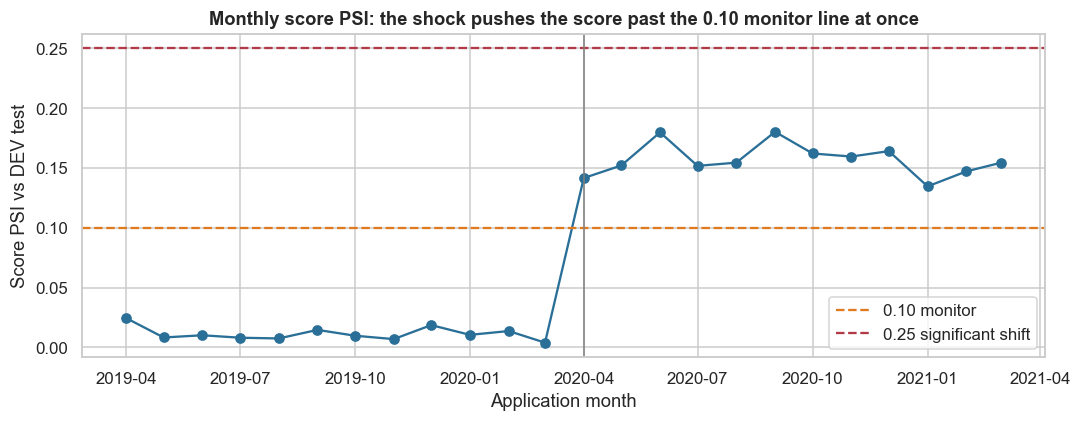

In [29]:
# Monitoring view: monthly score PSI vs the DEV test reference
mon = pd.concat([test.assign(pd_=pd_te.values), oot.assign(pd_=pd_oot.values)])
mon["month"] = mon.application_date.dt.to_period("M").dt.to_timestamp()
mpsi = mon.groupby("month").apply(lambda g: psi(pd_te, g.pd_), include_groups=False)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mpsi.index, mpsi.values, "o-", color="#2a6f97")
ax.axhline(0.10, ls="--", color="#e07a1f", label="0.10 monitor"); ax.axhline(0.25, ls="--", color="#b23a48", label="0.25 significant shift")
ax.axvline(pd.Timestamp("2020-04-01"), color="grey", lw=1)
ax.set_xlabel("Application month"); ax.set_ylabel("Score PSI vs DEV test"); ax.set_title("Monthly score PSI: the shock pushes the score past the 0.10 monitor line at once"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** - **Score PSI = 0.15, "monitor" (moderate shift).** Every shock month sits at 0.13–0.18, against ≤ 0.03 before. The monthly alarm would have fired in **April 2020, the first shock month**, more than a year before those loans' 12-month default outcomes were known.
- **Features:** YoY credit growth shows a **significant shift (PSI 0.47)**, because inflows collapsed in the lockdown. Minimum balance (0.16) and credit months active (0.10) are "monitor". Bureau, bounces, declines and vintage are stable (< 0.05).
- **A subtle but important point:** the bureau score's *distribution* stayed stable (PSI 0.04) even though its *relationship* with default weakened under the moratorium. PSI only detects **population shift**, not **concept drift**. That is why KS and calibration must also be tracked by vintage, as in Lendingkart's "three types of statistical tests".

### 7.10 Scorecard scaling to 300–900 and risk buckets A–F

**Scaling (industry-standard "points to double the odds"):** Score = 650 + (50 / ln 2) · [ln(odds_good:bad) − ln 20], clipped to 300–900. A score of 650 corresponds to good:bad odds of 20:1 (PD ≈ 4.8%), and **every 50 points doubles the odds of being good**. The buckets are fixed score bands (D-2-14): **A ≥ 750, B 700–749, C 650–699, D 600–649, E 550–599, F < 550**.

In [30]:
def to_score(p):
    p = np.asarray(p, float)
    return np.clip(650 + 50 / np.log(2) * (np.log((1 - p) / p) - np.log(20)), 300, 900).round()
BANDS = [-np.inf, 550, 600, 650, 700, 750, np.inf]; BUCKETS = ["F", "E", "D", "C", "B", "A"]
def bucket(s): return pd.cut(s, BANDS, labels=BUCKETS, right=False)
score_te, score_oot = to_score(pd_te), to_score(pd_oot)

def bucket_table(y, s, label):
    d = pd.DataFrame({"y": np.asarray(y), "b": bucket(np.asarray(s))})
    t = d.groupby("b", observed=False).agg(n=("y", "size"), bads=("y", "sum")).iloc[::-1]
    t["share"] = t.n / t.n.sum(); t["bad_rate"] = t.bads / t.n
    lo, hi = proportion_confint(t.bads, t.n.clip(lower=1), method="wilson"); t["CI_low"], t["CI_high"] = lo, hi
    t.columns = pd.MultiIndex.from_product([[label], t.columns]); return t
bt = bucket_table(yte, score_te, "DEV test").join(bucket_table(yoot, score_oot, "OOT"))
mono_dev = bt[("DEV test", "bad_rate")].is_monotonic_increasing; mono_oot = bt[("OOT", "bad_rate")].is_monotonic_increasing
chi_b = stats.chi2_contingency(pd.crosstab(bucket(score_te), yte.values))
print(f"Bad rate rises monotonically A→F: DEV test {mono_dev} | OOT {mono_oot};  chi-square bucket × default (test): p = {chi_b[1]:.3g}")
print(f"Score range on test: {score_te.min():.0f}–{score_te.max():.0f}, median {np.median(score_te):.0f}")
bt.round(4)

Bad rate rises monotonically A→F: DEV test True | OOT True;  chi-square bucket × default (test): p = 1.2e-141
Score range on test: 301–867, median 658


DEV test                                       OOT                                    
         n bads  share bad_rate CI_low CI_high     n bads  share bad_rate CI_low CI_high
b                                                                                       
A      603    8 0.0703   0.0133 0.0067  0.0260   647   11 0.0302   0.0170 0.0095  0.0302
B     1603   30 0.1868   0.0187 0.0131  0.0266  2448   47 0.1144   0.0192 0.0145  0.0254
C     2505   80 0.2919   0.0319 0.0257  0.0396  5212  227 0.2436   0.0436 0.0383  0.0494
D     2009  129 0.2341   0.0642 0.0543  0.0758  5857  402 0.2737   0.0686 0.0624  0.0754
E     1163  136 0.1355   0.1169 0.0997  0.1367  3987  529 0.1863   0.1327 0.1225  0.1436
F      699  192 0.0814   0.2747 0.2429  0.3089  3245  935 0.1517   0.2881 0.2728  0.3040

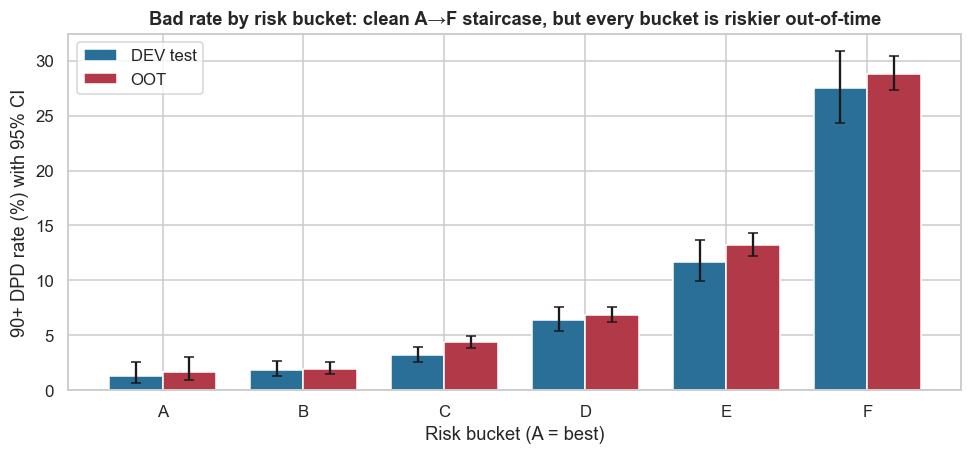

In [31]:
fig, ax = plt.subplots(figsize=(9, 4.3))
x = np.arange(6); w = 0.38
for i, (lab, c) in enumerate([("DEV test", "#2a6f97"), ("OOT", "#b23a48")]):
    br = bt[(lab, "bad_rate")] * 100
    err = [(bt[(lab, "bad_rate")] - bt[(lab, "CI_low")]) * 100, (bt[(lab, "CI_high")] - bt[(lab, "bad_rate")]) * 100]
    ax.bar(x + (i - 0.5) * w, br, w, yerr=err, capsize=3, color=c, label=lab)
ax.set_xticks(x); ax.set_xticklabels(bt.index.astype(str)); ax.set_xlabel("Risk bucket (A = best)"); ax.set_ylabel("90+ DPD rate (%) with 95% CI")
ax.set_title("Bad rate by risk bucket: clean A→F staircase, but every bucket is riskier out-of-time"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** - **Bad rates rise cleanly from A to F in both samples.** On DEV test: 1.3%, 1.9%, 3.2%, 6.4%, 11.7%, 27.5% (chi-square p ≈ 10⁻¹⁴¹). Each step roughly doubles risk, as the "50 points doubles the odds" scaling intends. The buckets are fit to drive credit policy. Scores range from 301 to 867 (median 658), inside the documented 300–900.
- **OOT:** the staircase holds, but the *population* moves down. F grows from 8% to 15% of applicants, A+B shrink from 26% to 14%, and buckets C–E are 0.4–1.6 pp riskier than before.
- **Zero-Touch:** an auto-approve lane for buckets A–B would cover about **26% of applicants at a bad rate of 1.9% or less** pre-shock. Lendingkart documents about 40% on Zero Touch. Reaching that share would mean extending the lane into the safest part of bucket C, which is a policy choice the CRO should make explicitly.

### 7.11 Two documented claims, tested: segment performance and approval uplift vs manual underwriting

1. *"Models perform better for new-to-credit MSMEs that have CIBIL scores of 651–700"* (CIO.com). We compare KS by bureau band on the DEV test set.
2. *"About 50% higher approval rates vs manual underwriting"* (AIM). We simulate a typical **manual policy**: approve only if bureau ≥ 700, vintage ≥ 3 years and no bounces (new-to-credit rejected). We then find the model cut-off with the *same bad rate* and compare approval rates.

In [32]:
seg = pd.cut(test.bureau_score, [0, 650, 700, 750, 901], labels=["≤650", "651–700", "701–750", ">750"], right=True).astype(str).replace("nan", "NTC (no score)")
seg_rows = []
for s in ["NTC (no score)", "≤650", "651–700", "701–750", ">750"]:
    msk = (seg == s).values
    k, a, g = ks_auc_gini(yte[msk], pd_te[msk])
    seg_rows.append((s, msk.sum(), yte[msk].mean(), k, a))
seg_tab = pd.DataFrame(seg_rows, columns=["bureau band", "n", "bad rate", "KS within band", "AUC within band"]).set_index("bureau band")
print(seg_tab.round(3))

manual = (test.bureau_score.fillna(0) >= 700) & (test.vintage_years.fillna(0) >= 3) & (test.cheque_bounces_6m == 0)
m_appr, m_bad = manual.mean(), yte[manual.values].mean()
order = np.argsort(-score_te); s_sorted = score_te[order]; y_sorted = yte.values[order]
cum_bad = np.cumsum(y_sorted) / np.arange(1, len(y_sorted) + 1)
k_star = np.max(np.where(cum_bad <= m_bad)[0]) + 1
mdl_appr = k_star / len(y_sorted)
print(f"\nManual policy : approval {m_appr:.1%}, bad rate {m_bad:.2%}")
print(f"Model at same bad rate: approval {mdl_appr:.1%} (cut-off score ≥ {s_sorted[k_star - 1]:.0f}) -> {mdl_appr / m_appr - 1:+.0%} more approvals")

                   n  bad rate  KS within band  AUC within band
bureau band                                                    
NTC (no score)   894    0.0810         33.0390           0.7070
≤650            1108    0.1710         37.5400           0.7470
651–700         2040    0.0800         32.9420           0.6970
701–750         2421    0.0380         29.2210           0.6640
>750            2119    0.0270         33.0420           0.6940

Manual policy : approval 34.7%, bad rate 2.62%
Model at same bad rate: approval 58.2% (cut-off score ≥ 643) -> +68% more approvals


**Takeaway:** - **The model separates risk inside every bureau band** (KS 29–38). That includes **new-to-credit businesses with no bureau score (KS 33, AUC 0.71)**, which is the core promise of cash-flow underwriting.
- The documented claim that the model works *best* for the 651–700 band is **not reproduced here** (KS 33, similar to the other bands). Our synthetic data has no mechanism that would create such an effect, so this result neither confirms nor refutes the claim.
- **Manual policy** (bureau ≥ 700, vintage ≥ 3 years, no bounces) approves **34.7%** at a **2.6%** bad rate. At the *same* bad rate, the model approves **58.2%** (cut-off score ≥ 643): **+68% more approvals with no extra risk**, comparable with Lendingkart's documented "about 50% higher approval rates". The extra approvals come from groups manual rules exclude wholesale: NTC businesses, young businesses, and businesses with one bounce but otherwise strong cash flows.

## 8. ML Section — one XGBoost model (the documented algorithm) vs the logistic scorecard

**Design (D-2-15):** sensible defaults, **no tuning** (400 trees, learning rate 0.05, depth 4, 80% row/column subsampling). The input is *all* candidate features plus one-hot categoricals: trees are not harmed by correlated inputs in the way logistic coefficients are. We compare KS/AUC on the same test and OOT sets, bootstrap the AUC difference, and explain the model with **SHAP values**. XGBoost computes these natively (`pred_contribs=True`), so no extra library is needed. A SHAP value is each feature's push, in log-odds, on one applicant's prediction.

In [33]:
def xgb_matrix(X, d):
    return pd.concat([X, pd.get_dummies(d[CAT], dtype=float).set_index(X.index)], axis=1)
Xtr_x = xgb_matrix(Xtr, train); Xte_x = xgb_matrix(Xte, test).reindex(columns=Xtr_x.columns, fill_value=0); Xoot_x = xgb_matrix(Xoot, oot).reindex(columns=Xtr_x.columns, fill_value=0)
xgbm = xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                         eval_metric="logloss", random_state=SEED, n_jobs=4)
xgbm.fit(Xtr_x, ytr)
px_tr, px_te, px_oot = (xgbm.predict_proba(X)[:, 1] for X in (Xtr_x, Xte_x, Xoot_x))
cmp_rows = []
for name, y, pl, px in [("train", ytr, pd_tr, px_tr), ("test (DEV)", yte, pd_te, px_te), ("OOT", yoot, pd_oot, px_oot)]:
    kl, al, gl = ks_auc_gini(y, pl); kx, ax_, gx = ks_auc_gini(y, px)
    cmp_rows.append((name, kl, kx, al, ax_, gl, gx, np.mean(pl), np.mean(px), y.mean()))
cmp = pd.DataFrame(cmp_rows, columns=["sample", "KS logit", "KS xgb", "AUC logit", "AUC xgb", "Gini logit", "Gini xgb",
                                      "mean PD logit", "mean PD xgb", "actual bad rate"]).set_index("sample")
diffs = []
yv, a1, a2 = yte.values, np.asarray(pd_te), px_te
for _ in range(500):
    i = boot_rng.integers(0, len(yv), len(yv)); diffs.append(roc_auc_score(yv[i], a2[i]) - roc_auc_score(yv[i], a1[i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
a_diff = roc_auc_score(yv, a2) - roc_auc_score(yv, a1)
print(f"AUC(XGB) − AUC(logit) on DEV test = {a_diff:+.4f}, 95% bootstrap CI [{lo:+.4f}, {hi:+.4f}]")
print(f"XGB score PSI (DEV test → OOT) = {psi(px_te, px_oot):.3f} vs logistic {psi(pd_te, pd_oot):.3f}")
cmp.round(4)

AUC(XGB) − AUC(logit) on DEV test = -0.0257, 95% bootstrap CI [-0.0369, -0.0140]
XGB score PSI (DEV test → OOT) = 0.156 vs logistic 0.152


,KS logit,KS xgb,AUC logit,AUC xgb,Gini logit,Gini xgb,mean PD logit,mean PD xgb,actual bad rate
sample,,,,,,,,,
train,37.6568,69.9635,0.7608,0.9315,0.5215,0.8630,0.0670,0.0669,0.0670
test (DEV),39.3151,35.6772,0.7617,0.7360,0.5235,0.4721,0.0688,0.0654,0.0670
OOT,38.4875,36.4288,0.7547,0.7441,0.5095,0.4882,0.0976,0.0999,0.1005


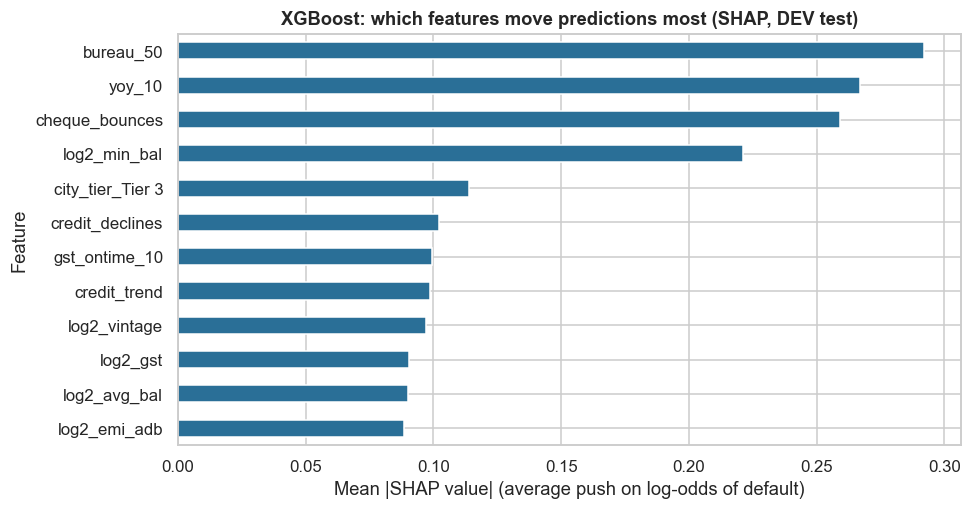

In [34]:
contrib = xgbm.get_booster().predict(xgb.DMatrix(Xte_x), pred_contribs=True)[:, :-1]      # last column = bias
shap_imp = pd.Series(np.abs(contrib).mean(axis=0), index=Xte_x.columns).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 4.8))
shap_imp.iloc[::-1].plot(kind="barh", color="#2a6f97", ax=ax)
ax.set_xlabel("Mean |SHAP value| (average push on log-odds of default)"); ax.set_ylabel("Feature")
ax.set_title("XGBoost: which features move predictions most (SHAP, DEV test)")
plt.tight_layout(); plt.show()

**Takeaway:** - **XGBoost with sensible defaults memorises the training data** (train AUC 0.93 vs 0.76 for logistic) and **generalises worse**: test AUC 0.736 vs 0.762. The difference of **−0.026 (95% bootstrap CI −0.037 to −0.014)** excludes zero, so XGBoost is significantly worse here. On OOT it is 0.744 vs 0.755. Score stability is similar (PSI 0.156 vs 0.152).
- **SHAP ranks the same drivers** as the logistic model: bureau score, YoY growth, cheque bounces, minimum balance, Tier 3, credit declines and GST discipline. That is reassuring for explainability, because the two models agree on *why* someone is risky.
- **Why Lendingkart's XGBoost can still be the right choice for them:** with 5,000+ raw variables and many interactions, trees find structure a hand-built scorecard cannot. With about 20 well-engineered, monotonic features and about 1,300 defaults, the logistic scorecard already captures the signal, and XGBoost mostly adds variance. Early stopping, shallower trees and monotonic constraints would likely close the gap, but tuning was out of scope by design (D-2-15).

## 9. Business Translation — approval vs bad rate, and expected loss in ₹

**Step-by-step logic** (per 10,000 applications, at each score cut-off):
1. Approve everyone at or above the cut-off. **Approval rate** = approved ÷ applications.
2. **Bad rate** = defaults among approved (actual outcomes on the test/OOT sample).
3. **Expected loss (EL)** = Σ PD × LGD × EAD over approved loans, using model PDs (what we would *provision*). **Realised loss** uses the actual defaults.
   - **EAD** (exposure at default) = 80% of the sanctioned amount: a 24-month amortising loan that defaults typically does so 6–9 months in, with about 80% still outstanding (assumption).
   - **LGD** (loss given default) = **65%** base: unsecured MSME loans with partial recoveries (assumption; sensitivity 55% / 75%).
4. **Net interest income** on good loans = **7% of the loan amount** over its life (≈ 20% yield − ≈ 10% cost of funds − ≈ 3% opex, on the average outstanding balance; assumption).
5. **Expected profit** = income on goods − realised loss on bads. The best cut-off maximises profit subject to the approved bad rate ≤ 5% (Section 3).

In [35]:
LGD, EAD_FACTOR, NIM = 0.65, 0.80, 0.07

def cutoff_table(d, pdv, s, cutoffs, lgd=LGD, nim=NIM):
    d = d.assign(pd_=np.asarray(pdv), score=np.asarray(s), ead=d.loan_amount_inr * EAD_FACTOR)
    k = 10_000 / len(d); rows = []
    for c in cutoffs:
        a = d[d.score >= c]
        el = (a.pd_ * lgd * a.ead).sum() * k; rl = (a.default_90dpd_12m * lgd * a.ead).sum() * k
        inc = (a.loan_amount_inr * (1 - a.default_90dpd_12m) * nim).sum() * k
        rows.append((c, len(a) / len(d), a.default_90dpd_12m.mean(), len(a) * k, a.loan_amount_inr.sum() * k / 1e7,
                     el / 1e7, rl / 1e7, inc / 1e7, (inc - rl) / 1e7))
    return pd.DataFrame(rows, columns=["cut-off score", "approval rate", "bad rate (approved)", "approved per 10k apps",
                                       "disbursed ₹ cr", "expected loss ₹ cr", "realised loss ₹ cr", "net interest ₹ cr", "profit ₹ cr"])
CUTS = [500, 550, 575, 600, 625, 650, 675, 700, 750]
ct_dev = cutoff_table(test, pd_te, score_te, CUTS); ct_oot = cutoff_table(oot, pd_oot, score_oot, CUTS)
feasible = ct_dev[ct_dev["bad rate (approved)"] <= 0.05]
best_cut = int(feasible.loc[feasible["profit ₹ cr"].idxmax(), "cut-off score"])
print(f"Profit-maximising cut-off on DEV test with bad rate <= 5%: score >= {best_cut}")
print("DEV test (per 10,000 applications):"); print(ct_dev.round(3).to_string(index=False))
print("\nOOT, same cut-offs:"); print(ct_oot.round(3).to_string(index=False))

Profit-maximising cut-off on DEV test with bad rate <= 5%: score >= 575
DEV test (per 10,000 applications):
 cut-off score  approval rate  bad rate (approved)  approved per 10k apps  disbursed ₹ cr  expected loss ₹ cr  realised loss ₹ cr  net interest ₹ cr  profit ₹ cr
           500         0.9720               0.0570             9,723.8410      1,097.7480             24.7640             22.7680            73.7770      51.0090
           550         0.9190               0.0490             9,185.5050      1,070.8360             21.8150             19.8750            72.2830      52.4070
           575         0.8650               0.0440             8,651.8290      1,037.0860             19.3170             17.7740            70.2030      52.4290
           600         0.7830               0.0370             7,830.3430        981.4470             16.2620             15.2170            66.6530      51.4360
           625         0.6820               0.0320             6,820.0890        9

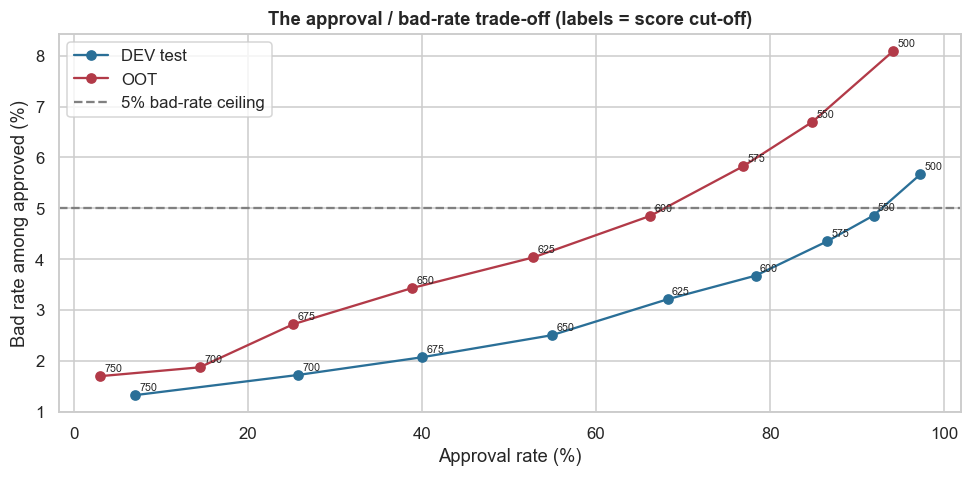

In [36]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for t, lab, c in [(ct_dev, "DEV test", "#2a6f97"), (ct_oot, "OOT", "#b23a48")]:
    ax.plot(t["approval rate"] * 100, t["bad rate (approved)"] * 100, "o-", color=c, label=lab)
    for _, r in t.iterrows():
        ax.annotate(int(r["cut-off score"]), (r["approval rate"] * 100, r["bad rate (approved)"] * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(5, ls="--", color="grey", label="5% bad-rate ceiling")
ax.set_xlabel("Approval rate (%)"); ax.set_ylabel("Bad rate among approved (%)")
ax.set_title("The approval / bad-rate trade-off (labels = score cut-off)"); ax.legend(); plt.tight_layout(); plt.show()

**Takeaway:** each step down in cut-off buys approvals at the cost of a higher bad rate. On DEV test, the **profit-maximising cut-off within the 5% bad-rate ceiling is 575**: 86.5% approval, 4.4% bad rate, about ₹52 crore expected profit per 10,000 applications (≈ ₹1,037 crore disbursed). Profit is flat between 550 and 600 (₹51.4–52.4 crore), so 575 is chosen because it has the lower bad rate. **In the shock (OOT), the same 575 cut-off breaches the ceiling** (5.8% bad rate). The cut-off must rise to **600** (4.9% bad rate, 66% approval), which is also the OOT profit maximum.

**Sensitivity (best / base / worst)** at the chosen cut-off, per 10,000 applications. Worst = LGD 75% and margin 6% in the OOT (shock) world; best = LGD 55% and margin 8% in the DEV world.

In [37]:
sens = []
for lab, d, pdv, s, lgd, nim in [("Best (DEV, LGD 55%, NIM 8%)", test, pd_te, score_te, 0.55, 0.08),
                                  ("Base (DEV, LGD 65%, NIM 7%)", test, pd_te, score_te, 0.65, 0.07),
                                  ("Base-OOT (shock, LGD 65%, NIM 7%)", oot, pd_oot, score_oot, 0.65, 0.07),
                                  ("Worst (shock, LGD 75%, NIM 6%)", oot, pd_oot, score_oot, 0.75, 0.06)]:
    r = cutoff_table(d, pdv, s, [best_cut], lgd, nim).iloc[0]
    sens.append((lab, r["approval rate"], r["bad rate (approved)"], r["disbursed ₹ cr"], r["realised loss ₹ cr"], r["net interest ₹ cr"], r["profit ₹ cr"]))
sens = pd.DataFrame(sens, columns=["scenario", "approval rate", "bad rate", "disbursed ₹ cr", "loss ₹ cr", "net interest ₹ cr", "profit ₹ cr"]).set_index("scenario")
sens.round(3)

,approval rate,bad rate,disbursed ₹ cr,loss ₹ cr,net interest ₹ cr,profit ₹ cr
scenario,,,,,,
"Best (DEV, LGD 55%, NIM 8%)",0.8650,0.0440,"1,037.0860",15.0400,80.2320,65.1930
"Base (DEV, LGD 65%, NIM 7%)",0.8650,0.0440,"1,037.0860",17.7740,70.2030,52.4290
"Base-OOT (shock, LGD 65%, NIM 7%)",0.7690,0.0580,796.8760,20.1920,53.0630,32.8710
"Worst (shock, LGD 75%, NIM 6%)",0.7690,0.0580,796.8760,23.2990,45.4830,22.1840


**Business reading:** - **Base case (normal conditions, cut-off 575):** per 10,000 applications, ≈ 8,650 loans and ₹1,037 crore disbursed. Realised credit loss ≈ ₹17.8 crore (1.7% of disbursal) against ≈ ₹70.2 crore net interest, so **≈ ₹52 crore profit**. Model-based expected loss (₹19.3 crore) slightly *over*-provisions vs realised, which is prudent.
- **Range:** ₹65 crore (best: LGD 55%, margin 8%) to ₹22 crore (worst: shock conditions, LGD 75%, margin 6%). Even the worst case stays profitable, but profit falls by ~60%.
- **In the shock, keeping the old cut-off** gives 5.8% bad rate, ₹20.2 crore of losses, and expected loss (₹18.5 crore) *under*-provisioned by ~9%. Raising the cut-off to 600 restores the bad-rate ceiling at about the same profit (₹33.0 crore vs ₹32.9 crore).
- **Versus manual underwriting:** at the manual policy's 2.6% bad rate, the model approves **+68% more businesses**. That is the growth lever: more MSMEs funded with no increase in risk.

**The risk is** that our LGD (65%), EAD (80%) and margin (7%) assumptions drive the ₹ figures directly. They should be replaced with the NBFC's own recovery and pricing data before the cut-off is finalised.

## 10. Recommendation and Decision

**Decision against the pre-registered rule (Section 3):** (i) test KS 39.3 ≥ 30 ✅ and OOT KS 38.5 ≥ 25 ✅; (ii) monotonic bad rate A→F in both samples ✅; (iii) score PSI 0.15 < 0.25 ✅, but in the "monitor" band, and OOT calibration fails (HL p = 0.005), so **recalibration is required** before use in shock conditions.

**I recommend:**
1. **Adopt the logistic scorecard as the champion model.** It beats default XGBoost on test (AUC 0.762 vs 0.736, significant), is fully explainable (every odds ratio has the expected sign), and is stable. Keep **XGBoost as a challenger** to be re-evaluated once the feature library grows towards Lendingkart's 5,000+ variables.
2. **Credit policy (normal conditions):** cut-off **575** (≈ 87% approval, ≈ 4.4% bad rate). **Zero-Touch auto-approval for buckets A–B** (≈ 26% of applicants, ≤ 1.9% bad rate). Manual review for C–D. Decline F, and E unless strong collateral or guarantees exist.
3. **Shock playbook:** if the monthly score PSI exceeds 0.10 for two consecutive months, raise the cut-off to **600** and apply an **industry overlay** (hospitality and transport: +1 bucket of risk; pharma and e-commerce: no penalty) until the model is recalibrated on post-shock vintages.
4. **Rollout:** a 3-month parallel run (the model scores every application while underwriters still decide), then go live with a 5% random "below cut-off" approval sample to keep learning about rejected applicants (reject inference).

**KPIs to monitor (monthly):** score PSI and feature CSI (alarm at 0.10 / 0.25); approval rate by bucket and by segment (tier, industry, NTC); early delinquency (30+ DPD at 3 and 6 months on book) by bucket vs expected; KS and HL by vintage once 12 months mature; expected vs realised loss; Zero-Touch share and turnaround time; GST/bank ratio data-quality check per channel.

## 11. Risks, Limitations and Next Steps

**Limits of synthetic data.**
- The relationships are *ours*. They were built from the documented feature families and plausible effect sizes, so the KS/Gini values show what the method *can* reach, not what Lendingkart's model achieves (which is "not disclosed").
- Real bank-statement features need heavy engineering (parsing, transaction categorisation, salary vs business credits, circular transactions between related accounts). Lendingkart builds 5,000–10,000 of them; we use about 20.
- **Reject inference:** we observe outcomes for every applicant. Real data only has outcomes for *approved* loans, so models are trained on a censored population. Techniques such as parcelling or bureau-based inference of rejected applicants' later behaviour are needed.
- **Balance-transfer triggers** (a documented feature family) are not simulated.

**Model risks.**
- **Population shift:** the OOT score PSI shows the population moved. In a real shock, also watch **concept drift** (the same features meaning something different), such as bureau scores frozen by the moratorium.
- **Fairness:** city tier and industry carry risk signal, but the policy must not unfairly exclude Tier-3 or specific communities. Monitor approval rates by segment.
- **Over-reliance on a single score:** keep policy rules (KYC, fraud, sector caps, exposure limits) outside the model.

**What real data would change.** We would re-derive the feature families from raw statements, validate on several OOT vintages, compute KS/PSI monthly, and calibrate LGD/EAD from actual recoveries instead of assumptions.

**Next steps.** (1) Recalibrate the intercept and the industry terms on recent vintages, (2) champion–challenger test of XGBoost vs the scorecard on live applications, (3) build the early-warning (EWS) trigger model mentioned in the case for the existing book, (4) set up a monthly monitoring pack: PSI, CSI, KS by vintage, bucket bad rates.

## 12. Appendix

**Formulas used**

| Quantity | Formula |
|---|---|
| WoE (bin i) | ln(%goodsᵢ / %badsᵢ) |
| IV | Σ (%goodsᵢ − %badsᵢ) · WoEᵢ |
| VIF | 1 / (1 − R²ⱼ), R²ⱼ from regressing feature j on all others |
| Cramér's V | √(χ² / (n·(min(r, c) − 1))) |
| Rank-biserial | r = 2U/(n₁n₂) − 1; single-feature AUC = (1 + |r|)/2 |
| Logistic model | ln(PD/(1 − PD)) = β₀ + Σ βⱼxⱼ; OR = e^β |
| KS | max over cut-offs of (cum% bads − cum% goods) |
| Gini | 2·AUC − 1 |
| Lift | decile bad rate / overall bad rate |
| Hosmer–Lemeshow | Σ_g (O_g − E_g)² / (E_g(1 − E_g/n_g)) ~ χ²(G − 2) |
| PSI | Σ (A% − E%) · ln(A% / E%) |
| Score | 650 + (50/ln 2)·(ln(odds_good) − ln 20), clipped 300–900 |
| Expected loss | EL = PD × LGD × EAD |

**Glossary (simple English)**

| Term | Meaning |
|---|---|
| DPD | Days past due: how late a repayment is. 90+ DPD is the usual default definition. |
| NTC | New-to-credit: no bureau history, so no score. |
| ADB | Average daily balance in the bank account. EMI/ADB shows how stretched the proposed EMI is. |
| WoE / IV | A bin's "safety" score / a feature's overall power to separate goods from bads. |
| VIF | How much a feature duplicates information already in the others. |
| Mann–Whitney U | Compares two groups by ranks; works on skewed data. |
| Rank-biserial r | Effect size for Mann–Whitney: how often one group beats the other. |
| Odds ratio | How many times the odds of default multiply for a one-unit change. |
| KS | The biggest gap between bads and goods as you move the cut-off. |
| AUC / Gini | The chance the model ranks a random bad above a random good / the same, rescaled to 0–1. |
| Lift | How concentrated defaults are in a group vs the average. |
| Calibration | Whether predicted default rates match actual ones. |
| Hosmer–Lemeshow | A test of calibration across risk groups. |
| PSI / CSI | How much the score / a feature distribution has shifted vs development. |
| Out-of-time (OOT) | A later period never used in building the model; the real test of durability. |
| LGD / EAD | Share of exposure lost after recoveries / amount owed at the time of default. |
| SHAP | Each feature's contribution to one prediction. |
| Reject inference | Estimating how rejected applicants would have performed. |